<a href="https://colab.research.google.com/github/joobnsucky/MyAI/blob/main/20213589_%EA%B9%80%EC%A4%80%EC%84%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 고양이·강아지 분류와 영역별 데이터 증강 비교
**20213589 김준석 | Deep Learning**

## 채점 및 실행 안내
1. 제출 ZIP을 풀고 `.ipynb`, `.h5`를 같은 폴더에 둡니다.
2. Colab에서 노트북을 열고 아래 **경로 및 실행 모드**를 확인한 뒤 위에서부터 실행합니다. **마지막 공식 benchmark 준비·평가 셀은 교수님 benchmark 데이터가 있을 때 실행합니다.**
3. 기본 모드 `evaluate`는 제출 모델을 재로딩하여 데이터셋의 test를 평가합니다. 데이터셋이 아직 연결되지 않아도 저장된 60회 로그와 그래프는 열람됩니다.
4. `train_selected`는 제출 모델과 같은 **VGG16 / T / seed123 / 40 epochs**를 새로 학습합니다. `train_all`은 5개 모델 × 4개 정책 × 3개 시드, 총 60회를 재실행합니다.
5. 재학습 결과와 증강 이미지는 **원본과 다른 새 출력 폴더**에 저장합니다. 기존 제출 모델을 자동으로 덮어쓰지 않습니다.

**로그 출처:** 아래 저장 출력은 기존 실험의 `history.csv`와 `test_metrics.json`에서 재구성한 실제 기록입니다. 이 정리 노트북에서 60회 재학습을 다시 수행한 것으로 표시하지 않습니다.

**핵심 설계:** CNN3/CNN5는 커널 크기, DeepCNN3는 깊이를 비교합니다. VGG16과 MobileNetV2도 사전학습 없이 학습했습니다. pooling·activation은 정책별로 바꾸지 않았습니다. MobileNetV2의 BN momentum은 모든 정책에서 0.9입니다.

**공식 채점만 실행할 때:** 1·2번 환경/경로 설정 셀 → 10번 benchmark 준비 셀 → 보호 블록 순서로 실행하면 됩니다. 재학습이나 test 결과 시각화를 실행할 필요가 없습니다. `SOURCE_ROOT`는 `benchmark` 폴더를 포함하는 상위 폴더입니다.
**제출 구성:** 노트북, Word 보고서, HDF5 모델 3개입니다. 실험 기록과 자동 영역 자료는 제출 HDF5의 보조 데이터 영역에 내장되어 별도 보조 파일 없이 실행됩니다.


**제출 전 코드 검사 완료:** TensorFlow 2.21.0 환경에서 기본 실행 흐름, 5개 모델의 합성 입력 1배치 학습, 4개 증강 함수, 합성 데이터의 학습·CSV·체크포인트·평가를 검사했습니다. 제출 HDF5 재로딩 전후 최대 예측 차이는 0.0입니다. 이는 실데이터 60회 재학습이나 새 test 정확도 측정이 아닙니다. 상세 검증 기록은 HDF5에 내장된 실험자료의 `submission_code_verification.json`에 있습니다.

**호환성 수정:** 저장 모델의 GlorotUniform 초기화 설정에서 값이 None인 input_axes/output_axes 및 Dense의 quantization_config만 제거했습니다. 학습 가중치는 변경하지 않았습니다. 노트북과 HDF5는 이번 수정본을 함께 사용하십시오.

Keras 3.12.0에서 기존 input_axes 오류를 재현하고 수정 HDF5의 기본 load_model 및 평가 실행을 확인했습니다. Keras 3.15.1 예측값과도 일치합니다.


## 1. 환경 설치
실험과 동일한 TensorFlow 2.21.0을 사용합니다. 설치를 먼저 수행한 새 Colab 런타임에서 실행하십시오. 기존에 다른 TensorFlow를 import한 세션이라면 설치 후 런타임을 다시 시작합니다. 영역 추출은 보존된 자동 마스크를 우선 사용하므로 동일 데이터셋에서는 모델 다운로드가 필요하지 않습니다.

In [ ]:
import sys, subprocess, importlib.metadata as metadata
required = {'tensorflow': '2.21.0'}
try:
    tf_version = metadata.version('tensorflow')
except metadata.PackageNotFoundError:
    tf_version = None
if tf_version != '2.21.0':
    if 'tensorflow' in sys.modules:
        raise RuntimeError('TensorFlow 설치 전에 런타임을 다시 시작하십시오.')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'tensorflow==2.21.0'])
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'numpy', 'pandas', 'pillow',
                       'opencv-python-headless', 'matplotlib', 'scikit-learn', 'h5py'])

0

## 2. 경로 및 실행 모드
데이터셋 폴더에는 `train/cats`, `train/dogs`, `validation/cats`, `validation/dogs`, `test/cats`, `test/dogs`가 있어야 합니다. 다른 Google 계정에서 실행하면 폴더를 자신의 Drive에 복사하거나 `BUNDLE_DIR`, `SOURCE_ROOT`를 수정합니다. 원본 이미지를 수정하지 않습니다.

In [ ]:
from pathlib import Path
import os
import sys

# Google Colab 환경 확인 및 Drive 연결
IN_COLAB = 'google.colab' in sys.modules or Path('/content').exists()

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

DEFAULT_DRIVE = Path('/content/drive/MyDrive/Colab Notebooks')
PREFIX = '20213589_김준석'

# 제출 노트북과 H5 모델이 들어 있는 폴더
BUNDLE_DIR = DEFAULT_DRIVE / PREFIX if IN_COLAB else Path.cwd()

# 원본 데이터셋 위치: 실제 이미지 폴더 경로와 일치해야 합니다.
SOURCE_ROOT = (
    DEFAULT_DRIVE / 'small_train_dataset_mid'
    if IN_COLAB
    else Path.cwd() / 'small_train_dataset_mid'
)

# 새 결과는 제출 폴더 안의 하위 폴더에 저장
OUTPUT_ROOT = BUNDLE_DIR / '실험결과'
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# evaluate: 제출 모델 평가 및 기존 로그 확인
# train_selected: 선택 모델 재학습
# train_all: 전체 60회 실험 재학습
RUN_MODE = 'evaluate'
REGENERATE_MASKS = False  # 기존 데이터는 저장된 자동 영역 마스크 사용

assert RUN_MODE in {'evaluate', 'train_selected', 'train_all'}

# 공식 benchmark 경로: SOURCE_ROOT/benchmark/{cats,dogs}
base_dir = str(SOURCE_ROOT)

print('제출 폴더:', BUNDLE_DIR)
print('데이터 폴더:', SOURCE_ROOT)
print('결과 저장 폴더:', OUTPUT_ROOT)
print('실행 모드:', RUN_MODE)
print('공식 benchmark 위치:', Path(base_dir) / 'benchmark')

Mounted at /content/drive
제출 폴더: /content/drive/MyDrive/Colab Notebooks/20213589_김준석
데이터 폴더: /content/drive/MyDrive/Colab Notebooks/small_train_dataset_mid
결과 저장 폴더: /content/drive/MyDrive/Colab Notebooks/20213589_김준석/실험결과
실행 모드: evaluate
공식 benchmark 위치: /content/drive/MyDrive/Colab Notebooks/small_train_dataset_mid/benchmark


In [ ]:
# 실험 기록은 제출 HDF5의 보조 데이터 영역에 보관합니다.
import h5py
with h5py.File(BUNDLE_DIR / f'{PREFIX}.h5', 'r') as archive:
    RECORDS_ZIP_BYTES = archive['submission_assets/records_zip'][()].tobytes()


In [ ]:
import json, hashlib, io, zipfile, shutil, time, gc, platform, base64
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, log_loss, confusion_matrix
from IPython.display import display
assert tf.__version__ == '2.21.0'
for gpu in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError: pass
SIZE = 150
CLASSES = {'cats': 0, 'dogs': 1}
ENGINE_VERSION = 'catdog-offline-v1.0'
EPOCHS = 40
SEEDS = [42, 123, 2026]
MODEL_NAMES = ['CNN3', 'CNN5', 'DeepCNN3', 'VGG16', 'MobileNetV2']
POLICIES = ['C0', 'C1', 'F', 'T']
CONFIG = {'epochs': 40, 'seeds': SEEDS, 'models': MODEL_NAMES, 'batch_size': 30,
          'learning_rate': 1e-4, 'data_mode': 'fixed_offline_one_per_source', 'include_c0': True}
with zipfile.ZipFile(io.BytesIO(RECORDS_ZIP_BYTES)) as bundle:
    RECORDS = json.loads(bundle.read('experiment_records.json'))
    FROZEN_MASKS = json.loads(bundle.read('auto_masks.json'))
    WORKER_SOURCE = bundle.read('auto_region_worker.py').decode('utf-8')
    EXPORT_CHECK = json.loads(bundle.read('export_check.json'))
EXPORT_CHECK['sha256'] = '05a01cb392e76b6dc47a0ee19f31291e2211f549d184ef1644110e1c70558603'  # 호환 설정 및 내장 자료 반영 파일
print('TensorFlow:', tf.__version__, 'GPU:', tf.config.list_physical_devices('GPU'))
print('기존 실험 기록:', len(RECORDS), 'runs')

TensorFlow: 2.21.0 GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
기존 실험 기록: 60 runs


## 3. 데이터 무결성 검사와 공통 전처리
EXIF 방향을 반영하고 RGB로 변환합니다. 원본 픽셀 해시로 정확히 중복된 이미지를 제외하며, test → validation → train 순서로 우선 보존합니다. 모든 정책은 동일한 분할을 사용합니다. 입력 정규화는 dataset 함수에서 한 번만 적용합니다.

In [ ]:
def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False).encode()).hexdigest()

def atomic_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding='utf-8')
    os.replace(tmp, path)

def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def setup_paths(source, output):
    source, output = (Path(source).resolve(), Path(output).resolve())
    if source == output or source in output.parents or output in source.parents:
        raise ValueError('원본과 출력 폴더는 서로 다른 형제 폴더여야 합니다.')
    if not all(((source / s / c).is_dir() for s in ['train', 'validation', 'test'] for c in CLASSES)):
        raise FileNotFoundError(f'train/validation/test 및 cats/dogs 폴더를 확인하세요: {source}')
    for name in ['shared', 'augmented', 'results', 'initial_weights']:
        (output / name).mkdir(parents=True, exist_ok=True)
    return (source, output)

def audit_dataset(source, output):
    records, excluded, seen = ([], [], {})
    for split in ['test', 'validation', 'train']:
        for cls, label in CLASSES.items():
            for p in sorted((source / split / cls).iterdir()):
                if not p.is_file() or p.suffix.lower() not in {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}:
                    continue
                rel = p.relative_to(source).as_posix()
                try:
                    raw = p.read_bytes()
                    with Image.open(io.BytesIO(raw)) as im:
                        rgb = ImageOps.exif_transpose(im).convert('RGB')
                        rgb.load()
                        w, h = rgb.size
                        sha = hashlib.sha256(np.asarray(rgb).tobytes() + f'{w},{h}'.encode()).hexdigest()
                except Exception as e:
                    excluded.append({'path': rel, 'reason': 'decode_error', 'detail': str(e)})
                    continue
                if sha in seen:
                    prior = seen[sha]
                    if prior['label'] != label:
                        raise ValueError(f"동일 이미지에 서로 다른 라벨: {rel}, {prior['path']}")
                    excluded.append({'path': rel, 'reason': 'exact_pixel_duplicate', 'kept': prior['path']})
                    continue
                rec = {'path': rel, 'split': split, 'class': cls, 'label': label, 'sha': sha, 'width': w, 'height': h}
                seen[sha] = rec
                records.append(rec)
    records = sorted(records, key=lambda r: r['path'])
    if any((not any((r['split'] == s and r['class'] == c for r in records)) for s in ['train', 'validation', 'test'] for c in CLASSES)):
        raise ValueError('빈 클래스 또는 분할이 있습니다.')
    obj = {'records': records, 'excluded': excluded, 'fingerprint': digest(records)}
    path = output / 'shared' / 'dataset_manifest.json'
    if path.exists() and read_json(path)['fingerprint'] != obj['fingerprint']:
        raise RuntimeError('원본 데이터가 이전 실험과 다릅니다. 새 OUTPUT_ROOT로 실험을 분리하세요.')
    atomic_json(path, obj)
    print(pd.DataFrame(records).groupby(['split', 'class']).size().unstack())
    print('제외:', len(excluded), '개. 원본 파일은 삭제/수정하지 않았습니다.')
    print('분할 간 정확히 일치하는 픽셀 중복을 제거했습니다. 유사 이미지/동일 개체 중복은 별도 검토가 필요합니다.')
    return obj

def rgb_array(source, rec, size=SIZE):
    with Image.open(source / rec['path']) as im:
        im = ImageOps.exif_transpose(im).convert('RGB')
        return np.asarray(im.resize((size, size), Image.Resampling.BILINEAR), dtype=np.uint8)

def load_split(source, manifest, split):
    rs = [r for r in manifest['records'] if r['split'] == split]
    return (np.stack([rgb_array(source, r) for r in rs]), np.array([r['label'] for r in rs], np.int32), rs)

In [ ]:
DATA_AVAILABLE = all((SOURCE_ROOT / split / cls).is_dir()
                     for split in ['train','validation','test'] for cls in ['cats','dogs'])
MANIFEST = None
if DATA_AVAILABLE:
    SOURCE_ROOT, OUTPUT_ROOT = setup_paths(SOURCE_ROOT, OUTPUT_ROOT)
    MANIFEST = audit_dataset(SOURCE_ROOT, OUTPUT_ROOT)
    recorded_fingerprint = RECORDS[0]['configuration.json']['dataset']
    print('보고서와 동일 데이터:', MANIFEST['fingerprint'] == recorded_fingerprint)
else:
    print('데이터셋 미연결: 기존 로그는 확인할 수 있습니다. 실행 평가/학습에는 SOURCE_ROOT를 설정하십시오.')
    if RUN_MODE != 'evaluate': raise FileNotFoundError(SOURCE_ROOT)

class       cats  dogs
split                 
test         500   500
train       1000  1000
validation   500   500
제외: 1 개. 원본 파일은 삭제/수정하지 않았습니다.
분할 간 정확히 일치하는 픽셀 중복을 제거했습니다. 유사 이미지/동일 개체 중복은 별도 검토가 필요합니다.
보고서와 동일 데이터: True


## 4. C0·C1·C2·C3 증강
- C0: resize와 1/255 scaling만 적용합니다.
- C1: 좌우 반전 확률 0.5, 회전 범위 ±15°입니다.
- F=C2: C1에 얼굴 영역 ±10° 회전을 추가합니다.
- T=C3: C1에 몸통 contrast 0.8–1.2, blur σ 0.3–0.8 또는 noise σ 0.01–0.03을 추가합니다.
- 두 영역이 모두 유효할 때만 확률 0.5로 지역 연산을 적용하며, 실패 이미지는 두 조건 모두 C1로 처리합니다.
- 이미지마다 시드별 변형 1개를 만들어 40 epochs 동안 재사용합니다. 원본 이미지 수가 늘어나는 방식이 아닙니다.

**자동 마스크:** 수동 지정이 아닌 Grounding DINO + SAM 결과입니다. 2,000장 중 729장이 유효했습니다. 구조 검사는 수행했으나 해부학적 정확성을 검증한 정답 라벨은 아닙니다.

In [ ]:
def polygon_mask(points):
    if not isinstance(points, dict) or points.get('encoding') != 'packbits150':
        raise ValueError('자동 150×150 packbits 마스크가 필요합니다.')
    raw = np.frombuffer(base64.b64decode(points['data'], validate=True), dtype=np.uint8)
    if len(raw) != (SIZE * SIZE + 7) // 8: raise ValueError('마스크 크기 오류')
    return np.unpackbits(raw)[:SIZE*SIZE].reshape(SIZE, SIZE).astype(np.float32)

def validate_region(item):
    if item.get('status') == 'skip':
        if not item.get('reason', '').strip():
            raise ValueError('skip 사유가 필요합니다.')
        return False
    if item.get('status') != 'valid':
        raise ValueError('valid 또는 skip 상태가 필요합니다.')
    f, t = (polygon_mask(item['face']), polygon_mask(item['torso']))
    if np.sum(f * t) > 0:
        raise ValueError('얼굴과 몸통 영역이 겹칩니다.')
    return True

def stable_rng(seed, sha, stream):
    n = int(hashlib.sha256(f'{seed}:{sha}:{stream}'.encode()).hexdigest()[:16], 16)
    return np.random.default_rng(n)

def geometry(seed, sha):
    rng = stable_rng(seed, sha, 'global')
    flip = bool(rng.random() < 0.5)
    angle = float(rng.uniform(-15, 15))
    return (flip, angle)

def warp(a, flip, angle, is_mask=False):
    a = np.fliplr(a).copy() if flip else a.copy()
    mat = cv2.getRotationMatrix2D(((SIZE - 1) / 2, (SIZE - 1) / 2), angle, 1)
    return cv2.warpAffine(a, mat, (SIZE, SIZE), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT if is_mask else cv2.BORDER_REFLECT_101, borderValue=0)

def soften(m):
    return np.clip(cv2.distanceTransform((m > 0.5).astype(np.uint8), cv2.DIST_L2, 3) / 2, 0, 1) * np.clip(m, 0, 1)

def augment(x, rec, seed, policy, annotations=None):
    x = x.astype(np.float32) / 255
    meta = {'sha': rec['sha'], 'policy': policy, 'seed': seed, 'eligible': False, 'regional_applied': False}
    if policy == 'C0':
        return (np.rint(x * 255).astype(np.uint8), meta)
    flip, angle = geometry(seed, rec['sha'])
    z = warp(x, flip, angle)
    meta.update(flip=flip, angle=angle)
    if policy == 'C1':
        return (np.rint(np.clip(z, 0, 1) * 255).astype(np.uint8), meta)
    item = annotations['items'][rec['sha']]
    eligible = validate_region(item)
    meta['eligible'] = eligible
    apply = bool(stable_rng(seed, rec['sha'], 'regional_gate').random() < 0.5)
    if not eligible or not apply:
        return (np.rint(np.clip(z, 0, 1) * 255).astype(np.uint8), meta)
    face = warp(polygon_mask(item['face']), flip, angle, True)
    torso = warp(polygon_mask(item['torso']), flip, angle, True)
    m = face if policy == 'F' else torso
    if (m > 0.5).sum() < 20:
        return (np.rint(np.clip(z, 0, 1) * 255).astype(np.uint8), meta)
    rng = stable_rng(seed, rec['sha'], 'regional_params')
    if policy == 'F':
        yy, xx = np.nonzero(m > 0.5)
        phi = float(rng.uniform(-10, 10))
        mat = cv2.getRotationMatrix2D((float(xx.mean()), float(yy.mean())), phi, 1)
        changed = cv2.warpAffine(z, mat, (SIZE, SIZE), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
        meta.update(operation='face_rotation', phi=phi)
    elif policy == 'T':
        op = ['contrast', 'blur', 'noise'][int(rng.integers(3))]
        if op == 'contrast':
            alpha = float(rng.uniform(0.8, 1.2))
            mu = (z * m[..., None]).sum((0, 1)) / max(m.sum(), 1)
            changed = mu + alpha * (z - mu)
            meta['alpha'] = alpha
        elif op == 'blur':
            sigma = float(rng.uniform(0.3, 0.8))
            changed = cv2.GaussianBlur(z, (5, 5), sigmaX=sigma)
            meta['sigma'] = sigma
        else:
            sigma = float(rng.uniform(0.01, 0.03))
            changed = z + rng.normal(0, sigma, z.shape).astype(np.float32)
            meta['sigma'] = sigma
        meta['operation'] = op
    else:
        raise ValueError(policy)
    m = soften(m)[..., None]
    out = z * (1 - m) + changed * m
    meta.update(regional_applied=True, area_fraction=float((m > 0).mean()))
    return (np.rint(np.clip(out, 0, 1) * 255).astype(np.uint8), meta)

def materialize(source, output, manifest, policy, seed, annotations=None):
    records = [r for r in manifest['records'] if r['split'] == 'train']
    spec = {'engine': ENGINE_VERSION, 'dataset': manifest['fingerprint'], 'policy': policy, 'seed': seed, 'annotations': digest(annotations) if annotations is not None else None, 'size': SIZE, 'mode': 'fixed_offline_one_per_source'}
    dest = output / 'augmented' / policy / f'seed_{seed}'
    dest.mkdir(parents=True, exist_ok=True)
    meta_path = dest / 'manifest.json'
    archive = dest / 'training_images.zip'
    if meta_path.exists() and archive.exists():
        saved = read_json(meta_path)
        if saved['spec'] != spec:
            raise RuntimeError('증강 캐시 설정 불일치: 새 OUTPUT_ROOT를 사용하세요.')
    else:
        rows = []
        tmp = archive.with_suffix('.tmp')
        with zipfile.ZipFile(tmp, 'w', compression=zipfile.ZIP_STORED) as zf:
            for i, r in enumerate(records):
                arr, info = augment(rgb_array(source, r), r, seed, policy, annotations)
                name = f"train/{r['class']}/{r['sha']}.png"
                buf = io.BytesIO()
                Image.fromarray(arr).save(buf, format='PNG')
                zf.writestr(name, buf.getvalue())
                info.update(name=name, source=r['path'], label=r['label'])
                rows.append(info)
                if (i + 1) % 250 == 0:
                    print(policy, seed, i + 1, '/', len(records))
        os.replace(tmp, archive)
        saved = {'spec': spec, 'rows': rows}
        atomic_json(meta_path, saved)
    with zipfile.ZipFile(archive) as zf:
        X = np.stack([np.array(Image.open(io.BytesIO(zf.read(r['name']))).convert('RGB')) for r in saved['rows']])
    y = np.array([r['label'] for r in saved['rows']], np.int32)
    return (X, y, saved)

def show_preview(source, manifest, X, metadata, n=6):
    records = [r for r in manifest['records'] if r['split'] == 'train']
    candidates = [i for i, r in enumerate(metadata['rows']) if r['regional_applied']]
    if not candidates:
        candidates = list(range(len(X)))
    ids = candidates[:n]
    fig, axes = plt.subplots(len(ids), 2, figsize=(6, 3 * len(ids)), squeeze=False)
    for row, i in enumerate(ids):
        axes[row, 0].imshow(rgb_array(source, records[i]))
        axes[row, 0].set_title('Original')
        axes[row, 1].imshow(X[i])
        axes[row, 1].set_title(metadata['rows'][i].get('operation', metadata['spec']['policy']))
        for ax in axes[row]:
            ax.axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
def prepare_masks(manifest):
    if not REGENERATE_MASKS:
        if FROZEN_MASKS['dataset_fingerprint'] != manifest['fingerprint']:
            raise ValueError('새 데이터는 REGENERATE_MASKS=True로 자동 영역 추출을 실행하십시오.')
        annotations = FROZEN_MASKS
    else:
        # 별도 subprocess로 PyTorch 추출 모델의 GPU 메모리를 학습 전에 반환합니다.
        if not tf.config.list_physical_devices('GPU'):
            raise RuntimeError('새 마스크 추출에는 Colab GPU 런타임이 필요합니다.')
        worker = OUTPUT_ROOT / 'shared' / 'auto_region_worker.py'
        worker.write_text(WORKER_SOURCE, encoding='utf-8')
        env_root = Path('/content/catdog_submission_region_env') if IN_COLAB else OUTPUT_ROOT / 'region_env'
        python = env_root / 'bin' / 'python'
        if not python.exists():
            subprocess.check_call([sys.executable, '-m', 'venv', '--system-site-packages', str(env_root)])
        subprocess.check_call([str(python), '-m', 'pip', 'install', '-q',
                               'transformers==4.57.1', 'huggingface-hub==0.36.0', 'torch', 'torchvision'])
        env = os.environ.copy(); env.update(USE_TF='0', USE_FLAX='0', PYTHONUNBUFFERED='1')
        subprocess.check_call([str(python), str(worker), '--source', str(SOURCE_ROOT),
                               '--output', str(OUTPUT_ROOT)], env=env)
        annotations = read_json(OUTPUT_ROOT / 'shared' / 'auto_region_annotations_v1.json')
    train = [r for r in manifest['records'] if r['split'] == 'train']
    usable = [validate_region(annotations['items'][r['sha']]) for r in train]
    if not any(usable): raise ValueError('유효한 지역 마스크가 없습니다.')
    atomic_json(OUTPUT_ROOT / 'shared' / 'frozen_masks.json', annotations)
    print('유효 영역:', sum(usable), '/', len(usable))
    return annotations

## 5. 다섯 모델의 구조
CNN3와 CNN5는 32–64–128–128 채널, 블록당 convolution 1개와 2×2 MaxPooling을 사용합니다. DeepCNN3는 블록당 3×3 convolution 2개입니다. 세 모델의 activation은 ReLU입니다. VGG16은 본래의 ReLU/MaxPooling을, MobileNetV2는 ReLU6·linear bottleneck·BN을 유지합니다. 모든 모델은 GAP와 sigmoid 출력, random initialization, dropout 없음으로 통일했습니다.

In [ ]:
def build_model(name):
    L = tf.keras.layers
    inp = L.Input((SIZE, SIZE, 3))
    x = inp
    if name in ['CNN3', 'CNN5', 'DeepCNN3']:
        k = 5 if name == 'CNN5' else 3
        reps = 2 if name == 'DeepCNN3' else 1
        for ch in [32, 64, 128, 128]:
            for _ in range(reps):
                x = L.Conv2D(ch, k, padding='same', activation='relu', use_bias=True)(x)
            x = L.MaxPooling2D(2)(x)
        x = L.GlobalAveragePooling2D()(x)
    elif name == 'VGG16':
        x = tf.keras.applications.VGG16(include_top=False, weights=None, input_tensor=inp, pooling='avg').output
    elif name == 'MobileNetV2':
        x = tf.keras.applications.MobileNetV2(include_top=False, weights=None, input_tensor=inp, pooling='avg', alpha=1.0).output
    else:
        raise ValueError(name)
    model = tf.keras.Model(inp, L.Dense(1, activation='sigmoid')(x), name=name)
    if name == 'MobileNetV2':
        for layer in model.layers:
            if isinstance(layer, tf.keras.layers.BatchNormalization): layer.momentum = 0.9
    return model

def dataset(X, y, batch, seed, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(len(X), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, tf.cast(y, tf.float32)), num_parallel_calls=1)
    opts = tf.data.Options()
    opts.experimental_deterministic = True
    opts.threading.private_threadpool_size = 1
    return ds.batch(batch).with_options(opts).prefetch(1)

def initialization(model, name, seed, output):
    root = output / 'initial_weights' / f'{ENGINE_VERSION}_{tf.__version__}' / f'{name}_seed{seed}'
    root.mkdir(parents=True, exist_ok=True)
    p = root / 'initial.weights.h5'
    if p.exists():
        model.load_weights(p)
    else:
        model.save_weights(p)
    return hashlib.sha256(p.read_bytes()).hexdigest()

## 6. 학습 및 최종 평가 함수
RMSprop(learning rate=0.0001), binary cross-entropy, batch size 30, 40 epochs입니다. checkpoint는 validation BCE 최저점으로 선택합니다. 동일 모델·시드의 초기 가중치를 공유하고 optimizer 상태는 매번 새로 만듭니다. 중단된 run은 초기 가중치부터 재시작하며 부분 로그를 완료로 취급하지 않습니다.

In [ ]:
def train_one(name, seed, policy, X, y, Xv, yv, manifest, output, config, aug_spec):
    spec = {'engine': ENGINE_VERSION, 'dataset': manifest['fingerprint'], 'model': name, 'seed': seed, 'policy': policy, 'config': config, 'aug_spec': aug_spec, 'tf': tf.__version__}
    run_id = digest(spec)[:16]
    run = output / 'results' / policy / f'{name}_seed{seed}_{run_id}'
    run.mkdir(parents=True, exist_ok=True)
    done = run / 'training_complete.json'
    if done.exists() and (run / 'best.keras').exists():
        print('이미 완료:', policy, name, seed)
        return run
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    tf.config.experimental.enable_op_determinism()
    model = build_model(name)
    initial_sha = initialization(model, name, seed, output)
    model.compile(optimizer=tf.keras.optimizers.RMSprop(learning_rate=config['learning_rate']), loss='binary_crossentropy', metrics=[tf.keras.metrics.BinaryAccuracy(name='accuracy')])
    atomic_json(run / 'configuration.json', dict(spec, initial_weights_sha256=initial_sha))
    ckpt = run / 'best.keras'
    hist_path = run / 'history.csv'
    cb = [tf.keras.callbacks.ModelCheckpoint(str(ckpt), monitor='val_loss', mode='min', save_best_only=True), tf.keras.callbacks.CSVLogger(str(hist_path), append=False), tf.keras.callbacks.TerminateOnNaN()]
    start = time.perf_counter()
    h = model.fit(dataset(X, y, config['batch_size'], seed, True), validation_data=dataset(Xv, yv, config['batch_size'], seed), epochs=config['epochs'], callbacks=cb, verbose=2, shuffle=False)
    elapsed = time.perf_counter() - start
    if len(h.history['loss']) != config['epochs'] or not np.isfinite(h.history['loss']).all():
        raise RuntimeError('학습이 정상 완료되지 않았습니다. 결과를 비교표에 넣지 않습니다.')
    hist = pd.read_csv(hist_path)
    best = int(hist.val_loss.idxmin())
    record = {'policy': policy, 'model': name, 'seed': seed, 'run_id': run_id, 'dataset': manifest['fingerprint'], 'config_hash': digest(config), 'initial_weights_sha256': initial_sha, 'best_epoch': best + 1, 'val_bce': float(hist.val_loss.iloc[best]), 'val_accuracy': float(hist.val_accuracy.iloc[best]), 'params': model.count_params(), 'seconds_per_epoch': elapsed / config['epochs'], 'tensorflow': tf.__version__, 'gpu': str(tf.config.list_physical_devices('GPU'))}
    atomic_json(done, record)
    fig, axs = plt.subplots(1, 2, figsize=(9, 3))
    for ax, metric in zip(axs, ['loss', 'accuracy']):
        ax.plot(hist.epoch + 1, hist[metric], label='train')
        ax.plot(hist.epoch + 1, hist['val_' + metric], label='validation')
        ax.set_xlabel('Epoch')
        ax.set_ylabel(metric)
        ax.legend()
    fig.tight_layout()
    fig.savefig(run / 'learning_curves.png', dpi=160)
    plt.show()
    plt.close(fig)
    del model
    gc.collect()
    return run

def evaluate_test(run, source, manifest, output, config):
    result = run / 'test_metrics.json'
    if result.exists():
        return read_json(result)
    X, y, records = load_split(source, manifest, 'test')
    model = tf.keras.models.load_model(run / 'best.keras')
    p = model.predict(dataset(X, y, config['batch_size'], 0), verbose=0).ravel()
    pred = (p >= 0.5).astype(int)
    m = read_json(run / 'training_complete.json')
    m.update(test_accuracy=float(accuracy_score(y, pred)), macro_f1=float(f1_score(y, pred, average='macro', zero_division=0)), roc_auc=float(roc_auc_score(y, p)), test_bce=float(log_loss(y, np.clip(p, 1e-07, 1 - 1e-07), labels=[0, 1])), confusion_matrix=confusion_matrix(y, pred, labels=[0, 1]).tolist())
    pd.DataFrame({'path': [r['path'] for r in records], 'sha': [r['sha'] for r in records], 'label': y, 'p_dog': p, 'prediction': pred}).to_csv(run / 'test_predictions.csv', index=False)
    atomic_json(result, m)
    del model, X
    gc.collect()
    return m

In [ ]:
NEW_RUNS = []
if RUN_MODE in {'train_selected', 'train_all'}:
    annotations = prepare_masks(MANIFEST)
    Xv, yv, _ = load_split(SOURCE_ROOT, MANIFEST, 'validation')
    jobs = [('VGG16', 'T', 123)] if RUN_MODE == 'train_selected' else [
        (m, p, s) for p in POLICIES for s in SEEDS for m in MODEL_NAMES]
    for policy, seed in dict.fromkeys((p, s) for m, p, s in jobs):
        X, y, aug_meta = materialize(SOURCE_ROOT, OUTPUT_ROOT, MANIFEST, policy, seed,
                                    annotations if policy in {'F', 'T'} else None)
        show_preview(SOURCE_ROOT, MANIFEST, X, aug_meta, n=2)
        for model_name, p, s in jobs:
            if (p, s) != (policy, seed): continue
            cfg = dict(CONFIG)
            if model_name == 'MobileNetV2':
                cfg.update(models=['MobileNetV2'], bn_momentum=0.9, revision='mobilenet-bn09-v1')
            run = train_one(model_name, seed, policy, X, y, Xv, yv, MANIFEST,
                            OUTPUT_ROOT, cfg, aug_meta['spec'])
            NEW_RUNS.append((run, cfg))
        del X, y; gc.collect()
    # 전 조건의 학습이 끝난 후 test를 평가합니다. test로 재학습 설정을 고르지 않습니다.
    for run, cfg in NEW_RUNS:
        evaluate_test(run, SOURCE_ROOT, MANIFEST, OUTPUT_ROOT, cfg)
    print('새 학습 및 평가 완료:', len(NEW_RUNS))
else:
    print('재학습 생략: evaluate 모드. 아래 셀에서 제출 모델을 평가합니다.')

재학습 생략: evaluate 모드. 아래 셀에서 제출 모델을 평가합니다.


## 7. 제출 모델 재로딩과 예측
제출 파일은 **전체 모델+학습된 가중치**를 포함한 HDF5입니다. 입력은 `(N,150,150,3)` RGB float32 `[0,1]`, 출력은 dog 확률입니다. 지역 증강은 학습 파이프라인이며 모델 내부에 들어 있지 않습니다.

60개 run의 validation BCE만으로 선정한 결과 VGG16/T/seed123, best epoch36이 선택되었습니다. 평균 테스트 정확도 비교에서 무증강 VGG16이 가장 높았다는 보고서의 결론과 별개입니다. `.keras → .h5` 변환 전후 예측 일치도 검사 결과는 자료 ZIP에 보존했습니다.

In [ ]:
MODEL_PATH = BUNDLE_DIR / f'{PREFIX}.h5'
actual_sha = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
assert actual_sha == EXPORT_CHECK['sha256'], '제출 가중치 파일 해시 불일치'
model = tf.keras.models.load_model(MODEL_PATH, compile=False)
assert model.input_shape == (None, 150, 150, 3) and model.output_shape == (None, 1)
model.compile(optimizer=tf.keras.optimizers.RMSprop(learning_rate=1e-4),
              loss='binary_crossentropy', metrics=['accuracy'])
print('재로딩 성공:', model.name, model.count_params(), 'parameters')
if MANIFEST is not None:
    Xt, yt, test_records = load_split(SOURCE_ROOT, MANIFEST, 'test')
    probabilities = model.predict(dataset(Xt, yt, 30, 0), verbose=1).ravel()
    predictions = (probabilities >= 0.5).astype(int)
    current_test = {'accuracy': float(accuracy_score(yt, predictions)),
                    'bce': float(log_loss(yt, np.clip(probabilities, 1e-7, 1-1e-7), labels=[0,1])),
                    'macro_f1': float(f1_score(yt, predictions, average='macro')),
                    'roc_auc': float(roc_auc_score(yt, probabilities)),
                    'confusion_matrix': confusion_matrix(yt, predictions).tolist()}
    display(current_test)
    atomic_json(OUTPUT_ROOT / 'submission_model_evaluation.json', current_test)
    del Xt
else:
    print('test 실측 재평가는 데이터 경로 설정 후 실행됩니다. 아래는 기존 저장 기록입니다.')

def predict_image(image_path):
    with Image.open(image_path) as image:
        x = np.asarray(ImageOps.exif_transpose(image).convert('RGB').resize((150,150), Image.Resampling.BILINEAR), dtype=np.float32) / 255
    probability = float(model(x[None], training=False).numpy()[0,0])
    return {'class': 'dog' if probability >= 0.5 else 'cat', 'p_dog': probability}

재로딩 성공: VGG16 14715201 parameters
34/34 ━━━━━━━━━━━━━━━━━━━━ 8s 112ms/step


{'accuracy': 0.725,
 'bce': 0.5447006256419573,
 'macro_f1': 0.7249667209732378,
 'roc_auc': 0.8045800000000001,
 'confusion_matrix': [[357, 143], [132, 368]]}

## 8. 새 학습 모델의 HDF5 저장
재학습 실행 시 validation BCE가 가장 낮은 새 checkpoint를 별도 파일로 저장합니다. 아래의 예측 일치 검사는 고정 난수 입력을 이용한 **파일 변환 검사**이며 테스트 성능 평가가 아닙니다.

In [ ]:
if NEW_RUNS:
    selected_run, _ = min(NEW_RUNS, key=lambda r: read_json(r[0]/'training_complete.json')['val_bce'])
    selected_model = tf.keras.models.load_model(selected_run / 'best.keras', compile=False)
    selected_model.compile(optimizer=tf.keras.optimizers.RMSprop(learning_rate=1e-4),
                           loss='binary_crossentropy', metrics=['accuracy'])
    export_path = OUTPUT_ROOT / f'{PREFIX}_재학습모델.h5'
    selected_model.save(export_path)
    reloaded = tf.keras.models.load_model(export_path, compile=False)
    probe = np.random.default_rng(123).uniform(0,1,(4,150,150,3)).astype(np.float32)
    before = selected_model(probe, training=False).numpy()
    after = reloaded(probe, training=False).numpy()
    np.testing.assert_allclose(before, after, rtol=1e-6, atol=1e-7)
    print('저장:', export_path, '최대 예측 차이:', float(np.abs(before-after).max()))

## 9. 실제 60회 학습 로그와 결과 비교
다음 셀은 동봉한 기존 `history.csv` 60개와 완료·평가 기록을 읽습니다. **아래 출력은 기존 실험 결과를 복원한 것으로, 정리 노트북을 새로 60회 실행했다는 의미가 아닙니다.** 재실행 결과는 별도 OUTPUT_ROOT에 저장되어 원래 보고서 결과와 섞이지 않습니다.

곡선은 train/validation accuracy와 loss이며, 별표는 validation loss로 선택한 epoch의 단일 test 평가입니다. epoch별 test 평가를 수행한 것으로 해석하면 안 됩니다.

In [ ]:
def validate_saved_records(records):
    keys = set(); initial = {}
    for r in records:
        c, done, test = r['configuration.json'], r['training_complete.json'], r['test_metrics.json']
        key = (c['model'], c['policy'], c['seed'])
        assert key not in keys; keys.add(key)
        h = pd.read_csv(io.StringIO(r['history.csv']))
        assert list(h.epoch) == list(range(40))
        assert np.isfinite(h[['accuracy','loss','val_accuracy','val_loss']]).all().all()
        assert c['tf'] == done['tensorflow'] == '2.21.0'
        assert c['dataset'] == done['dataset'] == test['dataset']
        assert done['run_id'] == test['run_id']
        assert done['config_hash'] == digest(c['config'])
        assert int(h.val_loss.idxmin()) + 1 == done['best_epoch']
        initial.setdefault((c['model'],c['seed']), set()).add(c['initial_weights_sha256'])
        if c['model'] == 'MobileNetV2':
            assert c['config']['bn_momentum'] == 0.9 and c['config']['revision'] == 'mobilenet-bn09-v1'
    assert keys == {(m,p,s) for m in MODEL_NAMES for p in POLICIES for s in SEEDS}
    assert all(len(v) == 1 for v in initial.values())
    print('검증 완료: 60 runs × 40 epochs; 학습 및 test 기록 60/60')
validate_saved_records(RECORDS)
summary = pd.DataFrame([dict(model=r['configuration.json']['model'],
                            policy=r['configuration.json']['policy'], seed=r['configuration.json']['seed'],
                            **{k:r['test_metrics.json'][k] for k in ['test_accuracy','test_bce','macro_f1','roc_auc']})
                        for r in RECORDS])
display(summary.groupby(['model','policy'])[['test_accuracy','test_bce','macro_f1','roc_auc']].agg(['mean','std']))

검증 완료: 60 runs × 40 epochs; 학습 및 test 기록 60/60


test_accuracy            test_bce            macro_f1  \
                            mean       std      mean       std      mean   
model       policy                                                         
CNN3        C0          0.650000  0.009644  0.634824  0.008627  0.649188   
            C1          0.631333  0.014189  0.636470  0.003790  0.625469   
            F           0.631000  0.013528  0.636699  0.003442  0.625474   
            T           0.633667  0.011060  0.635574  0.002932  0.631032   
CNN5        C0          0.684333  0.004933  0.587447  0.012636  0.683688   
            C1          0.686333  0.007506  0.593294  0.009524  0.685708   
            F           0.684333  0.004041  0.592445  0.011503  0.683758   
            T           0.682667  0.000577  0.594182  0.009171  0.681852   
DeepCNN3    C0          0.685667  0.008083  0.591212  0.009694  0.685044   
            C1          0.693000  0.008185  0.592591  0.008232  0.692540   
            F           0.690333  0.011240  0.593472  0.008232  0.689941   
            T           0.690667  0.007506  0.592891  0.008584  0.690061   
MobileNetV2 C0          0.603000  0.002646  0.685628  0.026276  0.602177   
            C1          0.593667  0.021595  0.709061  0.033111  0.585938   
            F           0.596000  0.016643  0.704697  0.014132  0.585205   
            T           0.593333  0.011590  0.733692  0.038534  0.585555   
VGG16       C0          0.721667  0.018009  0.552368  0.016860  0.720566   
            C1          0.709000  0.019468  0.565299  0.012023  0.708265   
            F           0.709333  0.021825  0.565529  0.020792  0.708913   
            T           0.716000  0.008544  0.560531  0.020936  0.713470   

                               roc_auc            
                         std      mean       std  
model       policy                                
CNN3        C0      0.010558  0.701845  0.009329  
            C1      0.020786  0.695929  0.006419  
            F       0.019668  0.695355  0.006052  
            T       0.012823  0.695592  0.007184  
CNN5        C0      0.004194  0.762549  0.015439  
            C1      0.007199  0.759251  0.010730  
            F       0.004027  0.760232  0.011995  
            T       0.000960  0.757164  0.011665  
DeepCNN3    C0      0.008026  0.760235  0.005732  
            C1      0.008142  0.755251  0.005553  
            F       0.011378  0.754564  0.004643  
            T       0.007644  0.755655  0.005213  
MobileNetV2 C0      0.001310  0.644391  0.005019  
            C1      0.016614  0.633889  0.022655  
            F       0.012304  0.645495  0.019868  
            T       0.013868  0.628035  0.014889  
VGG16       C0      0.018146  0.793955  0.016726  
            C1      0.019087  0.783753  0.013918  
            F       0.022249  0.782345  0.018472  
            T       0.011097  0.791997  0.017012

In [ ]:
def plot_saved_runs(model_name, policy):
    subset = sorted([r for r in RECORDS if r['configuration.json']['model']==model_name and r['configuration.json']['policy']==policy], key=lambda r:r['configuration.json']['seed'])
    fig, axes = plt.subplots(3,2,figsize=(11,9))
    table = []
    for i,r in enumerate(subset):
        h = pd.read_csv(io.StringIO(r['history.csv'])); t = r['test_metrics.json']; e = t['best_epoch']
        seed = r['configuration.json']['seed']
        for j,(metric,testkey) in enumerate([('accuracy','test_accuracy'),('loss','test_bce')]):
            ax=axes[i,j];ax.plot(h.epoch+1,h[metric],label='Train');ax.plot(h.epoch+1,h['val_'+metric],label='Validation')
            ax.scatter(e,t[testkey],marker='*',s=120,label='Test once');ax.axvline(e,color='gray',ls=':')
            ax.set(title=f'{model_name} / {policy} / seed {seed}: {metric}',xlabel='Epoch');ax.legend();ax.grid(alpha=.2)
        best=h.iloc[e-1];table.append({'seed':seed,'epoch':e,'train_accuracy':best.accuracy,'validation_accuracy':best.val_accuracy,
                                      'test_accuracy':t['test_accuracy'],'train_loss':best.loss,'validation_loss':best.val_loss,'test_bce':t['test_bce']})
    plt.tight_layout();plt.show();display(pd.DataFrame(table))

### 저장된 실험 결과: CNN3 / C0

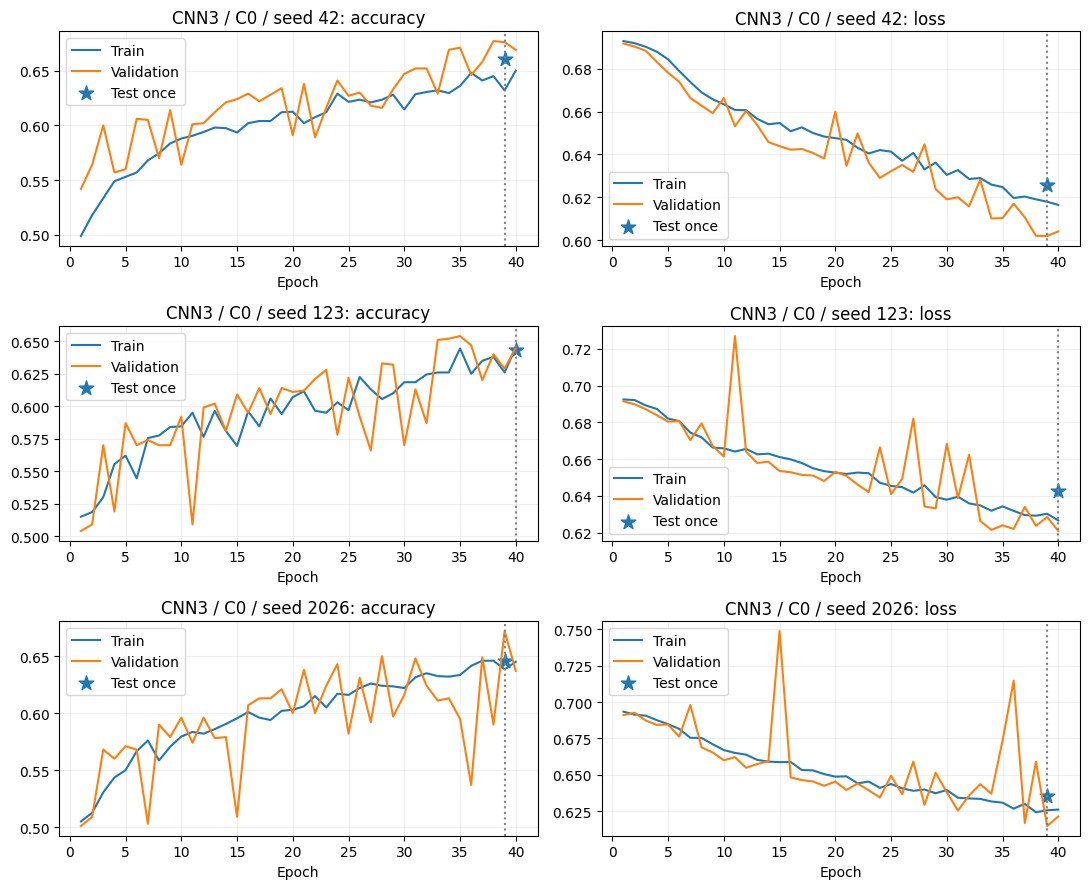

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,39,0.6320,0.676,0.661,0.617880,0.601887,0.625732
1,123,40,0.6455,0.645,0.643,0.626633,0.620899,0.642896
2,2026,39,0.6385,0.672,0.646,0.625837,0.615046,0.635845


In [ ]:
plot_saved_runs('CNN3', 'C0')

### 저장된 실험 결과: CNN3 / C1

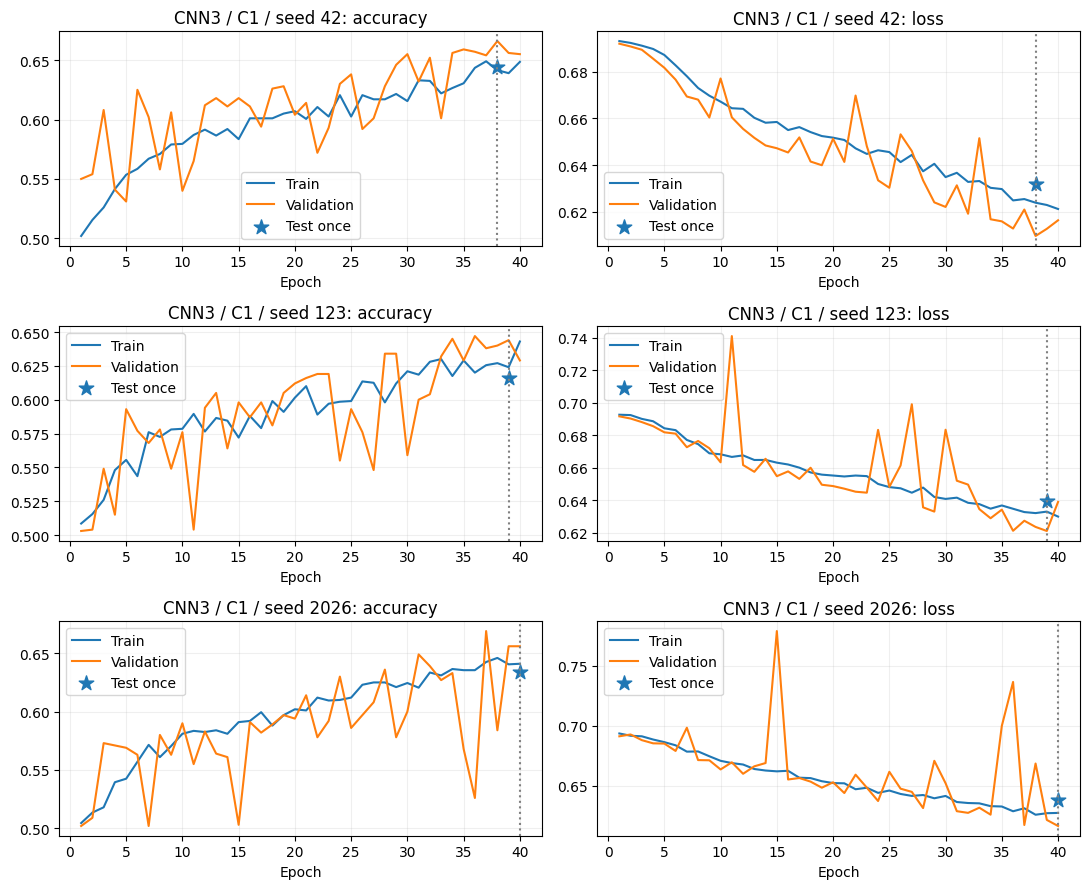

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,38,0.6415,0.666,0.644,0.623956,0.609735,0.632139
1,123,39,0.6240,0.644,0.616,0.632945,0.621012,0.639175
2,2026,40,0.6410,0.656,0.634,0.627085,0.616167,0.638096


In [ ]:
plot_saved_runs('CNN3', 'C1')

### 저장된 실험 결과: CNN3 / F

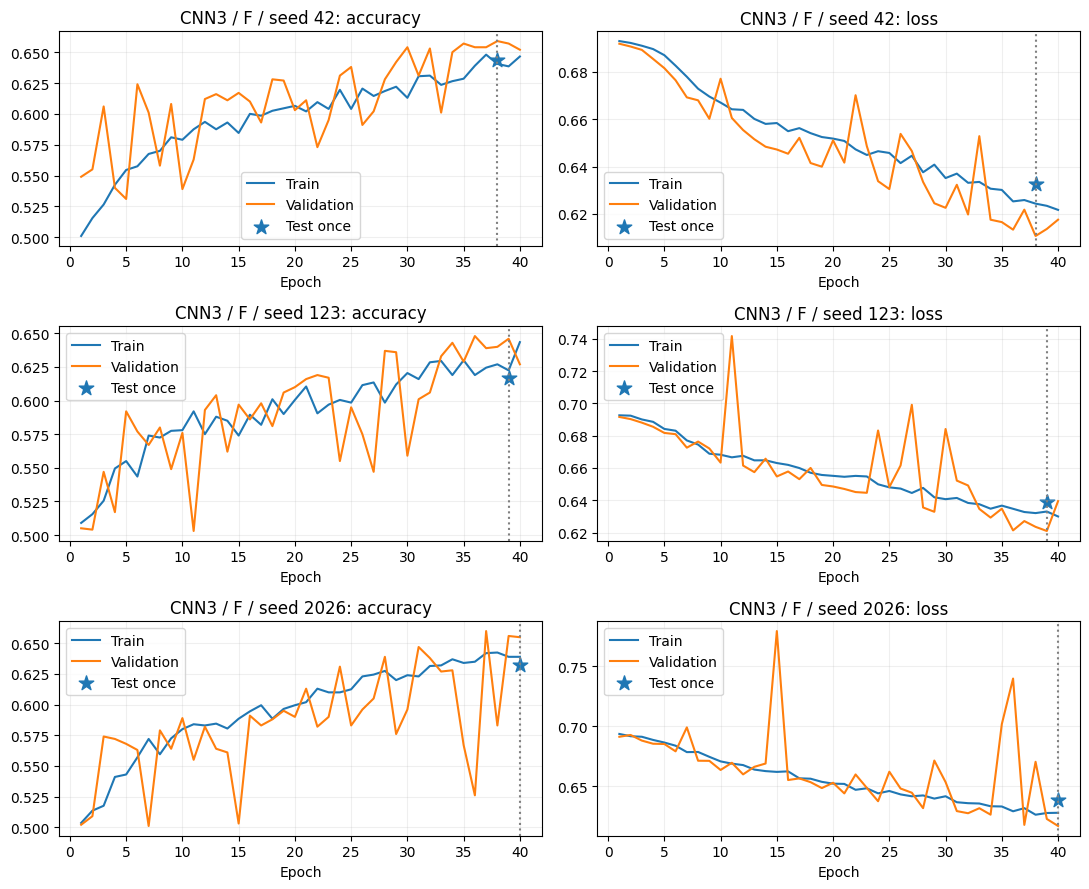

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,38,0.6405,0.659,0.644,0.624298,0.610615,0.632739
1,123,39,0.6225,0.646,0.617,0.633044,0.620991,0.638971
2,2026,40,0.6390,0.655,0.632,0.627676,0.616664,0.638388


In [ ]:
plot_saved_runs('CNN3', 'F')

### 저장된 실험 결과: CNN3 / T

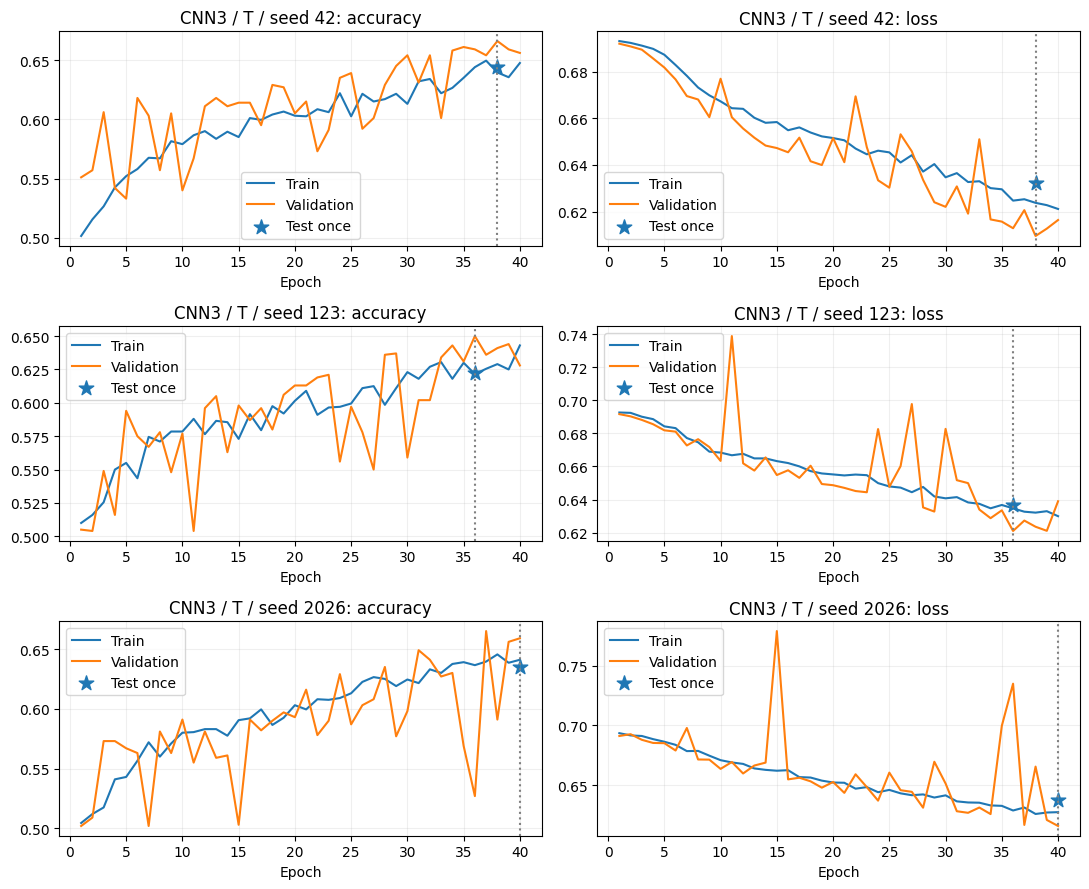

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,38,0.6395,0.666,0.644,0.623797,0.609614,0.632246
1,123,36,0.6215,0.650,0.622,0.634668,0.620986,0.636700
2,2026,40,0.6410,0.659,0.635,0.627332,0.615753,0.637776


In [ ]:
plot_saved_runs('CNN3', 'T')

### 저장된 실험 결과: CNN5 / C0

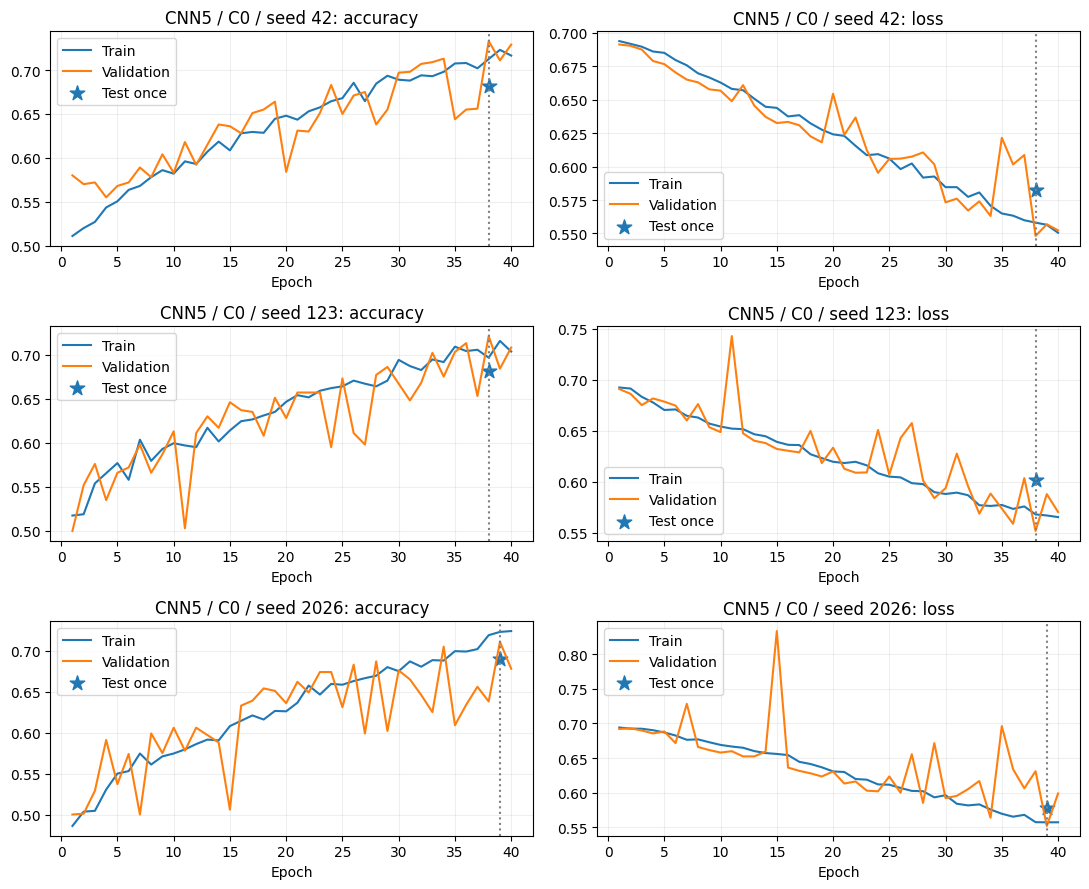

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,38,0.7125,0.733,0.682,0.558081,0.548083,0.582704
1,123,38,0.6965,0.721,0.681,0.567995,0.551774,0.601768
2,2026,39,0.7230,0.711,0.690,0.557085,0.551796,0.577868


In [ ]:
plot_saved_runs('CNN5', 'C0')

### 저장된 실험 결과: CNN5 / C1

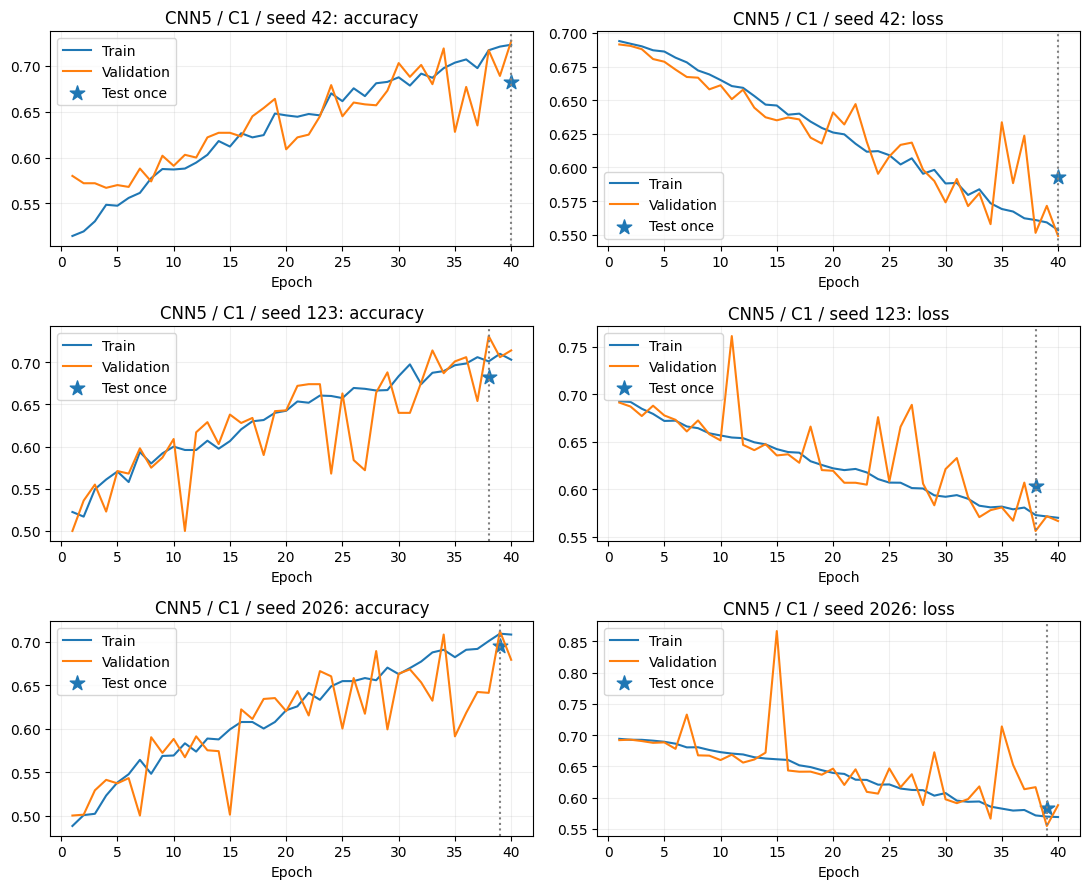

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,40,0.723,0.727,0.682,0.553438,0.549033,0.592673
1,123,38,0.701,0.731,0.682,0.572593,0.555823,0.603114
2,2026,39,0.709,0.712,0.695,0.569764,0.554776,0.584097


In [ ]:
plot_saved_runs('CNN5', 'C1')

### 저장된 실험 결과: CNN5 / F

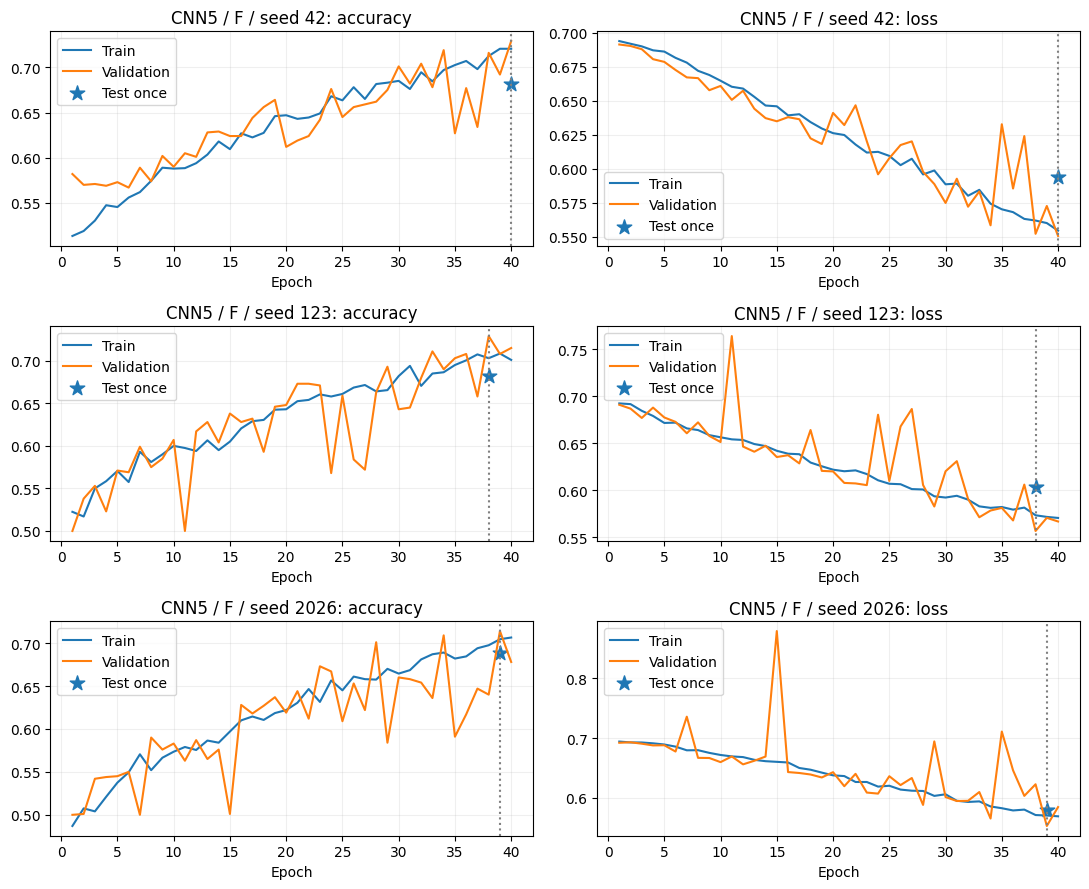

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,40,0.7205,0.729,0.682,0.554545,0.550614,0.593796
1,123,38,0.7030,0.729,0.682,0.573492,0.556786,0.603213
2,2026,39,0.7045,0.714,0.689,0.570338,0.552828,0.580326


In [ ]:
plot_saved_runs('CNN5', 'F')

### 저장된 실험 결과: CNN5 / T

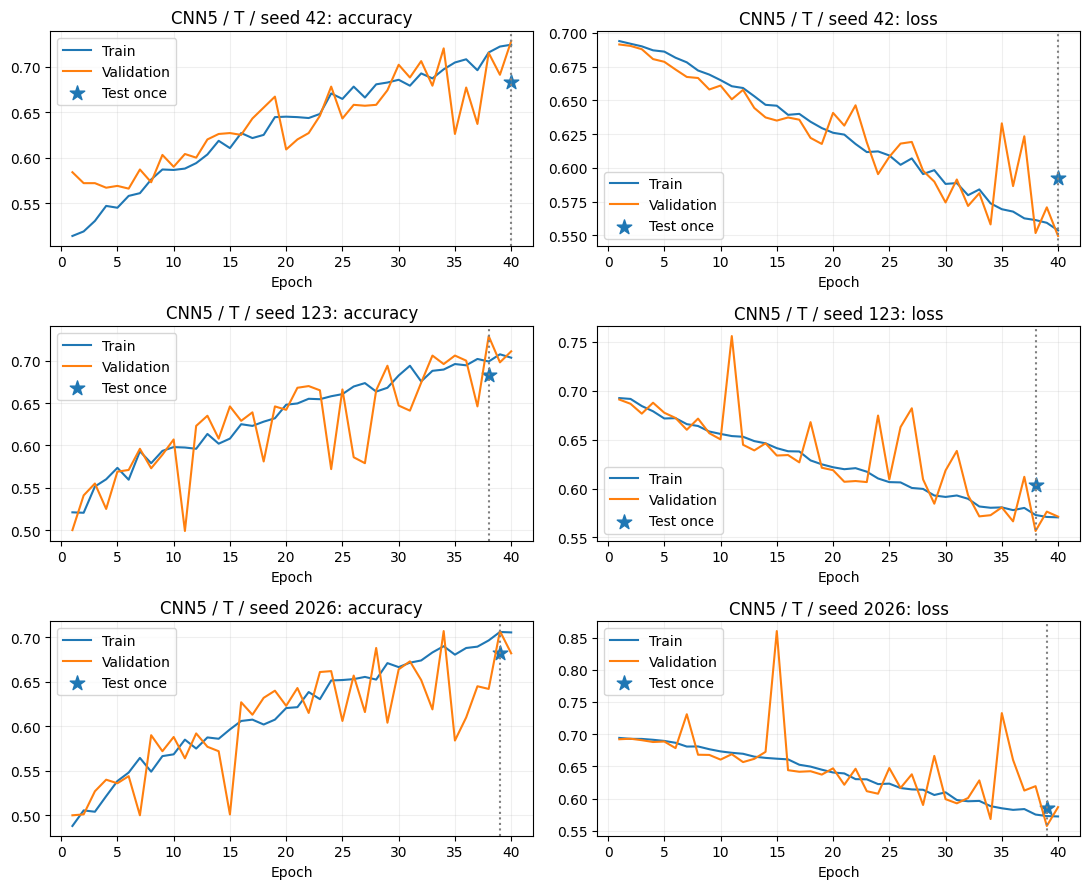

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,40,0.724,0.728,0.683,0.553752,0.549614,0.592663
1,123,38,0.699,0.729,0.683,0.572899,0.556562,0.604017
2,2026,39,0.706,0.707,0.682,0.572814,0.557406,0.585865


In [ ]:
plot_saved_runs('CNN5', 'T')

### 저장된 실험 결과: DeepCNN3 / C0

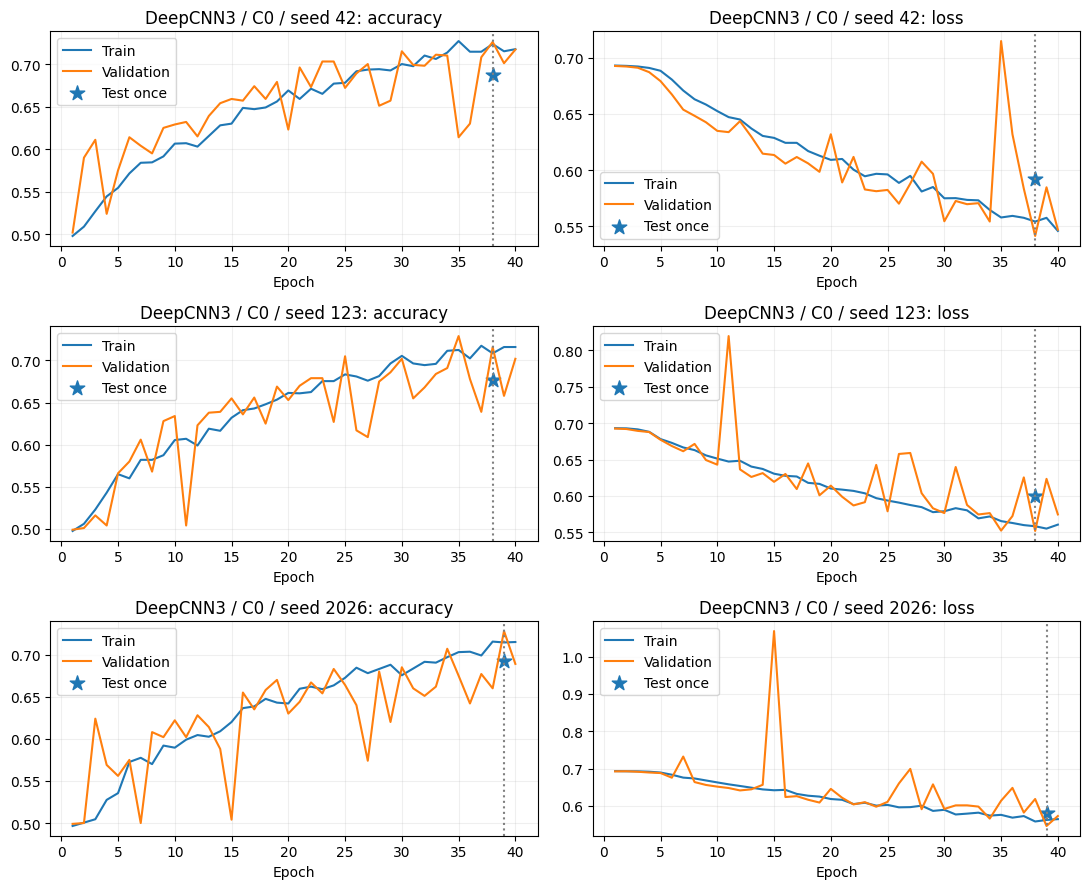

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,38,0.7235,0.726,0.687,0.554193,0.541355,0.592074
1,123,38,0.7085,0.716,0.677,0.558349,0.551848,0.600446
2,2026,39,0.7145,0.728,0.693,0.562454,0.546329,0.581116


In [ ]:
plot_saved_runs('DeepCNN3', 'C0')

### 저장된 실험 결과: DeepCNN3 / C1

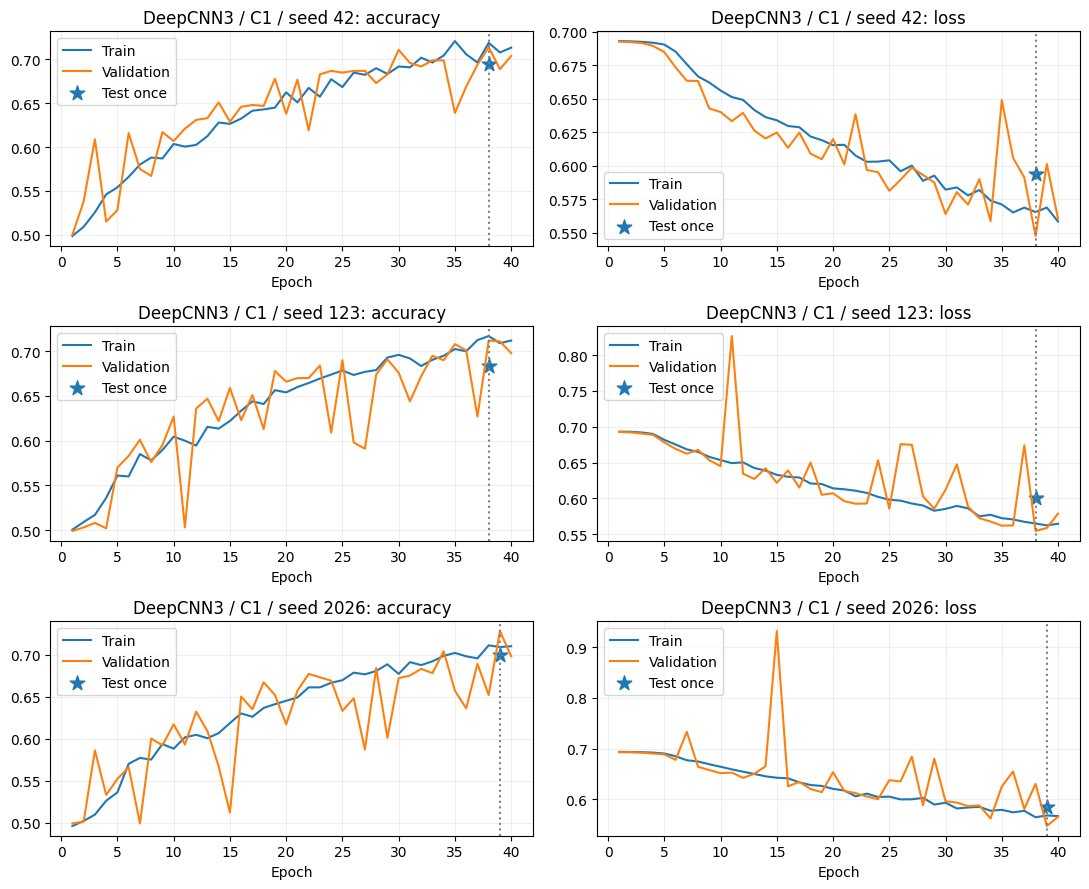

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,38,0.719,0.714,0.695,0.565592,0.547758,0.593648
1,123,38,0.717,0.712,0.684,0.564790,0.554355,0.600242
2,2026,39,0.709,0.728,0.700,0.567564,0.546672,0.583881


In [ ]:
plot_saved_runs('DeepCNN3', 'C1')

### 저장된 실험 결과: DeepCNN3 / F

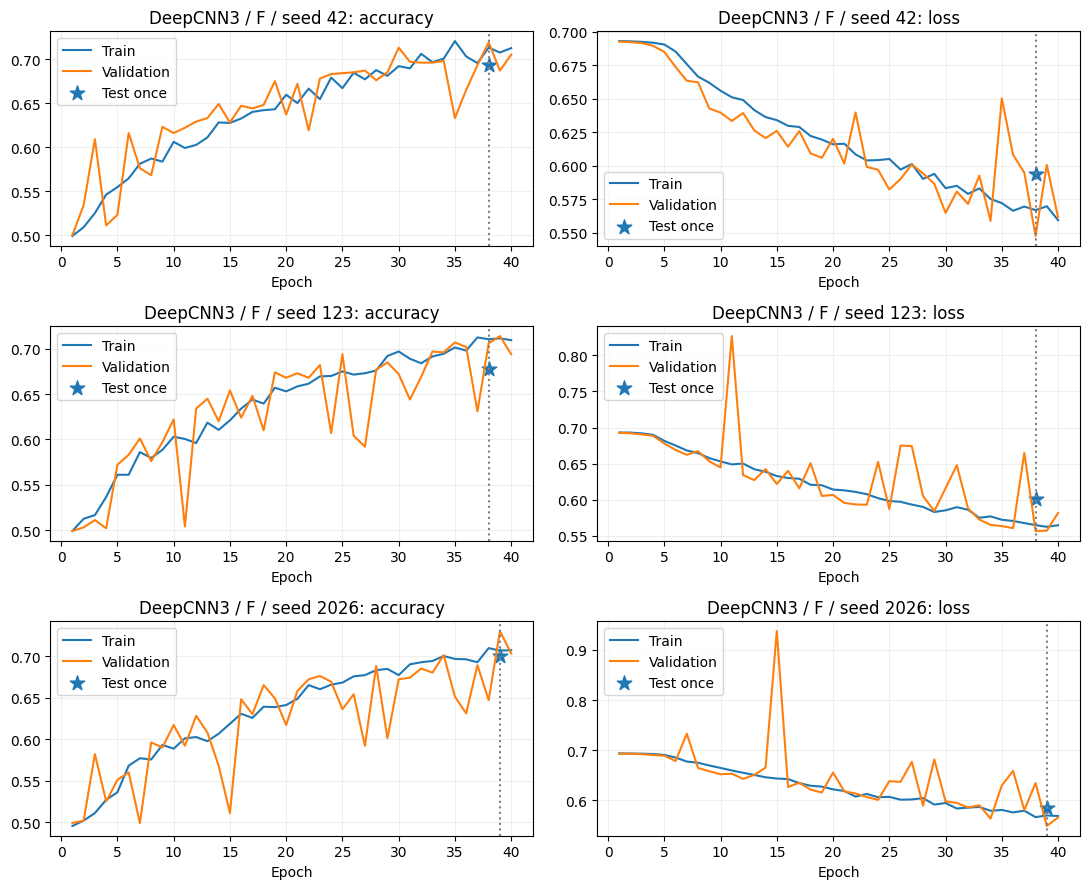

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,38,0.7130,0.719,0.693,0.566960,0.547669,0.593795
1,123,38,0.7105,0.706,0.678,0.564757,0.556686,0.601537
2,2026,39,0.7065,0.730,0.700,0.569269,0.548184,0.585083


In [ ]:
plot_saved_runs('DeepCNN3', 'F')

### 저장된 실험 결과: DeepCNN3 / T

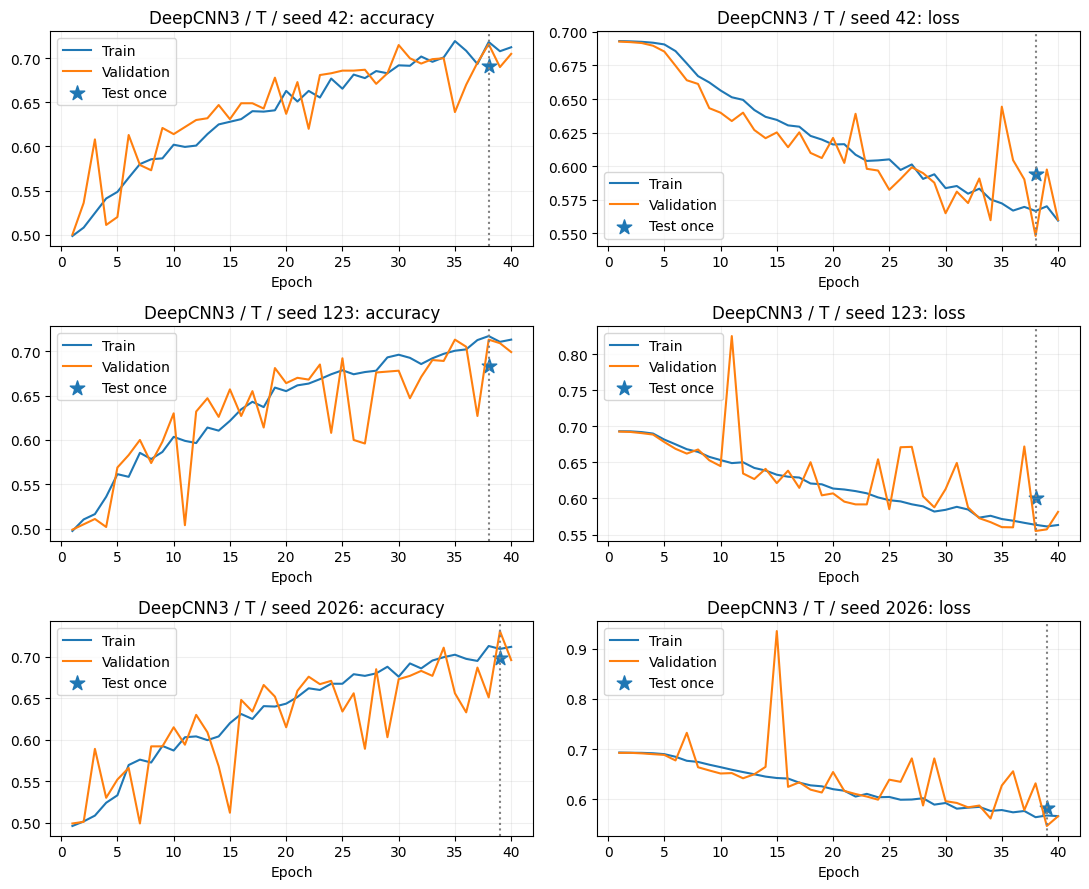

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,38,0.7185,0.716,0.691,0.566590,0.547958,0.594245
1,123,38,0.7170,0.713,0.683,0.563506,0.554967,0.600717
2,2026,39,0.7095,0.731,0.698,0.568082,0.547159,0.583711


In [ ]:
plot_saved_runs('DeepCNN3', 'T')

### 저장된 실험 결과: VGG16 / C0

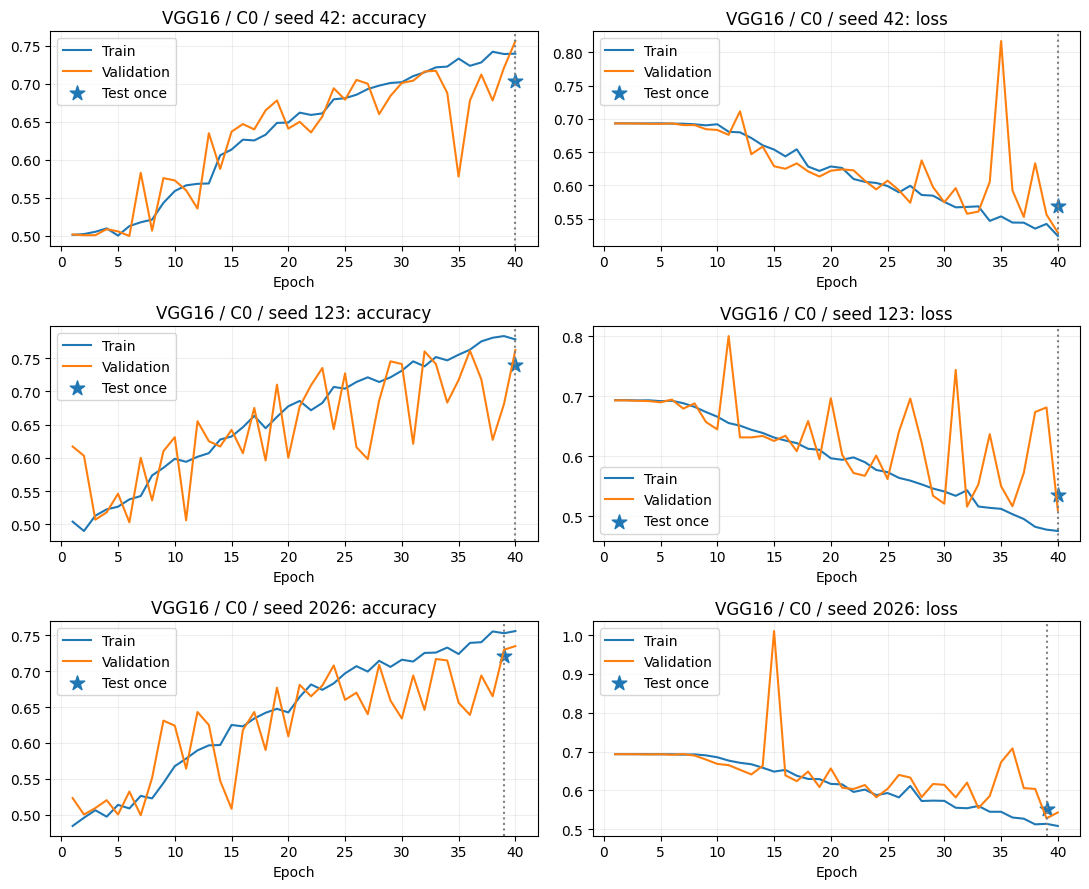

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,40,0.7395,0.756,0.704,0.523943,0.528992,0.569292
1,123,40,0.7780,0.762,0.740,0.475319,0.509550,0.535573
2,2026,39,0.7530,0.730,0.721,0.513800,0.528009,0.552239


In [ ]:
plot_saved_runs('VGG16', 'C0')

### 저장된 실험 결과: VGG16 / C1

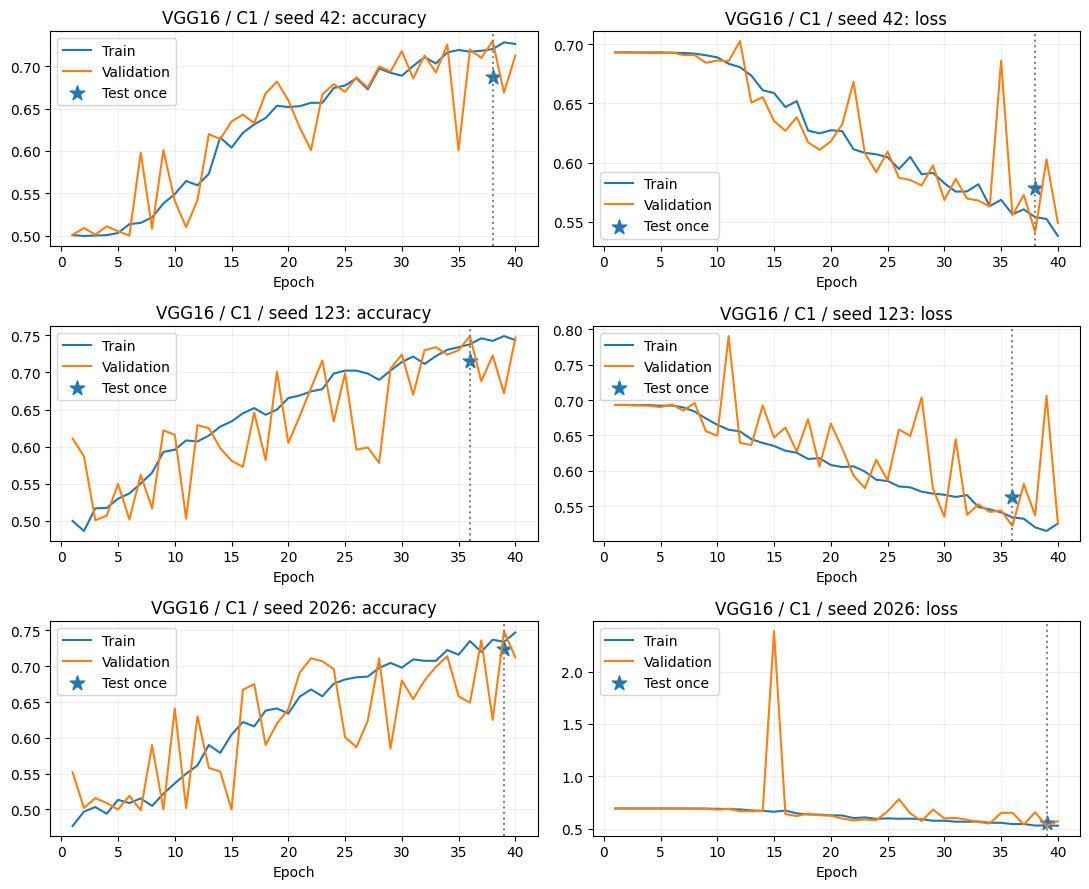

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,38,0.7205,0.730,0.687,0.554006,0.541440,0.578238
1,123,36,0.7380,0.749,0.716,0.534035,0.521968,0.563188
2,2026,39,0.7340,0.749,0.724,0.531630,0.526156,0.554470


In [ ]:
plot_saved_runs('VGG16', 'C1')

### 저장된 실험 결과: VGG16 / F

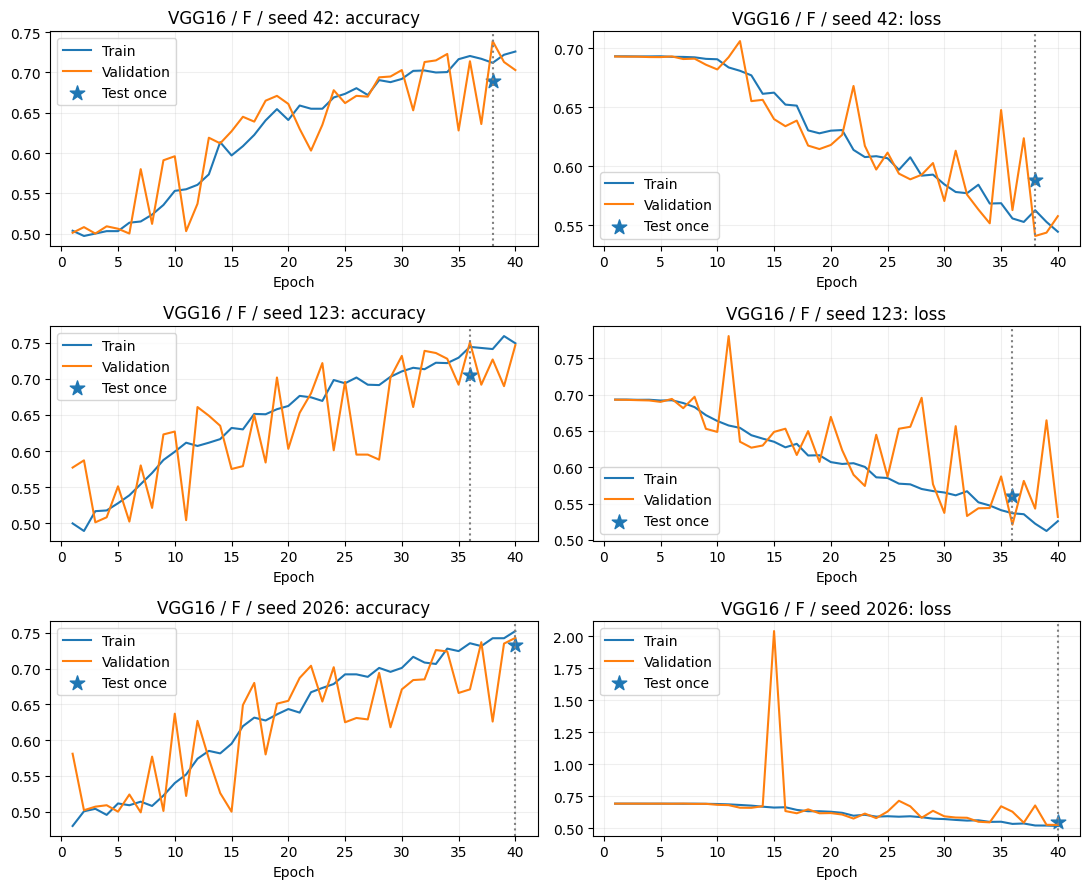

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,38,0.7120,0.739,0.690,0.562581,0.540742,0.588376
1,123,36,0.7445,0.751,0.705,0.536695,0.520934,0.560493
2,2026,40,0.7525,0.743,0.733,0.518815,0.527164,0.547718


In [ ]:
plot_saved_runs('VGG16', 'F')

### 저장된 실험 결과: VGG16 / T

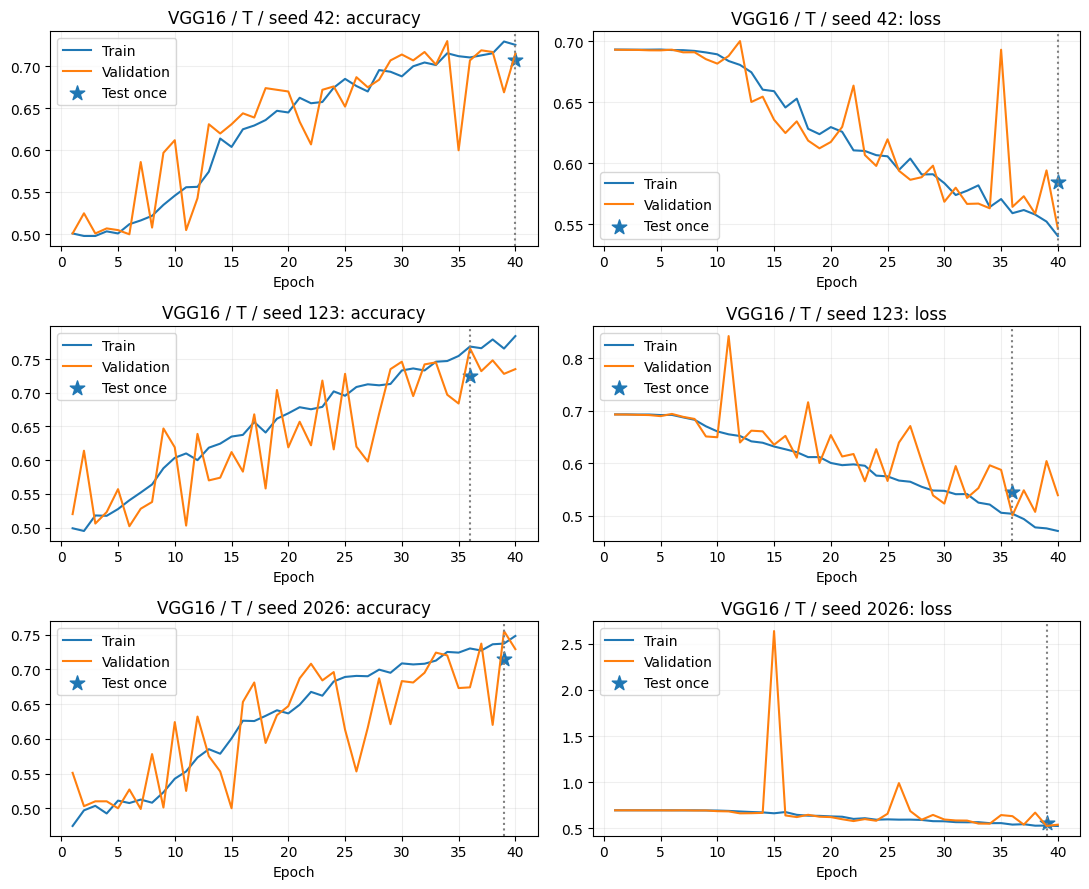

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,40,0.7255,0.715,0.708,0.540299,0.546269,0.584269
1,123,36,0.7685,0.766,0.725,0.503727,0.500739,0.544701
2,2026,39,0.7370,0.755,0.715,0.527080,0.523581,0.552625


In [ ]:
plot_saved_runs('VGG16', 'T')

### 저장된 실험 결과: MobileNetV2 / C0

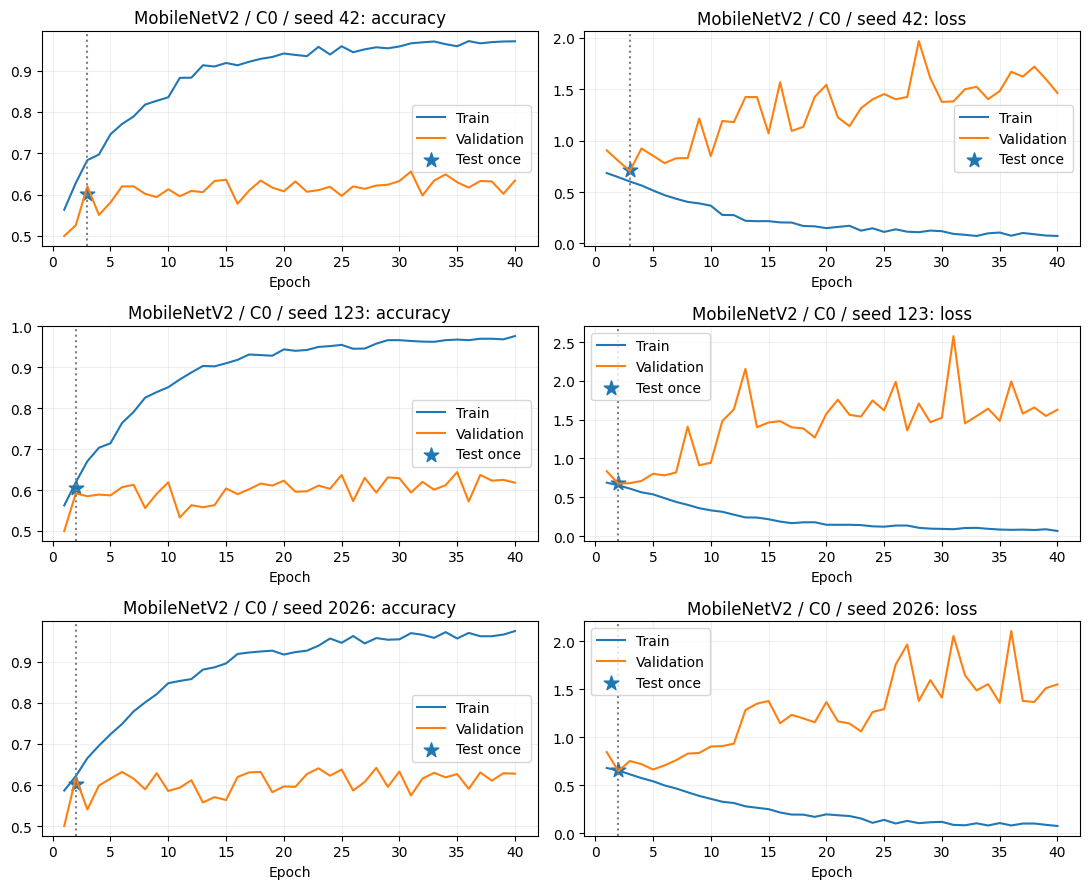

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,3,0.6835,0.620,0.601,0.602470,0.704848,0.712474
1,123,2,0.6190,0.592,0.606,0.653762,0.674891,0.684449
2,2026,2,0.6220,0.618,0.602,0.653483,0.649336,0.659962


In [ ]:
plot_saved_runs('MobileNetV2', 'C0')

### 저장된 실험 결과: MobileNetV2 / C1

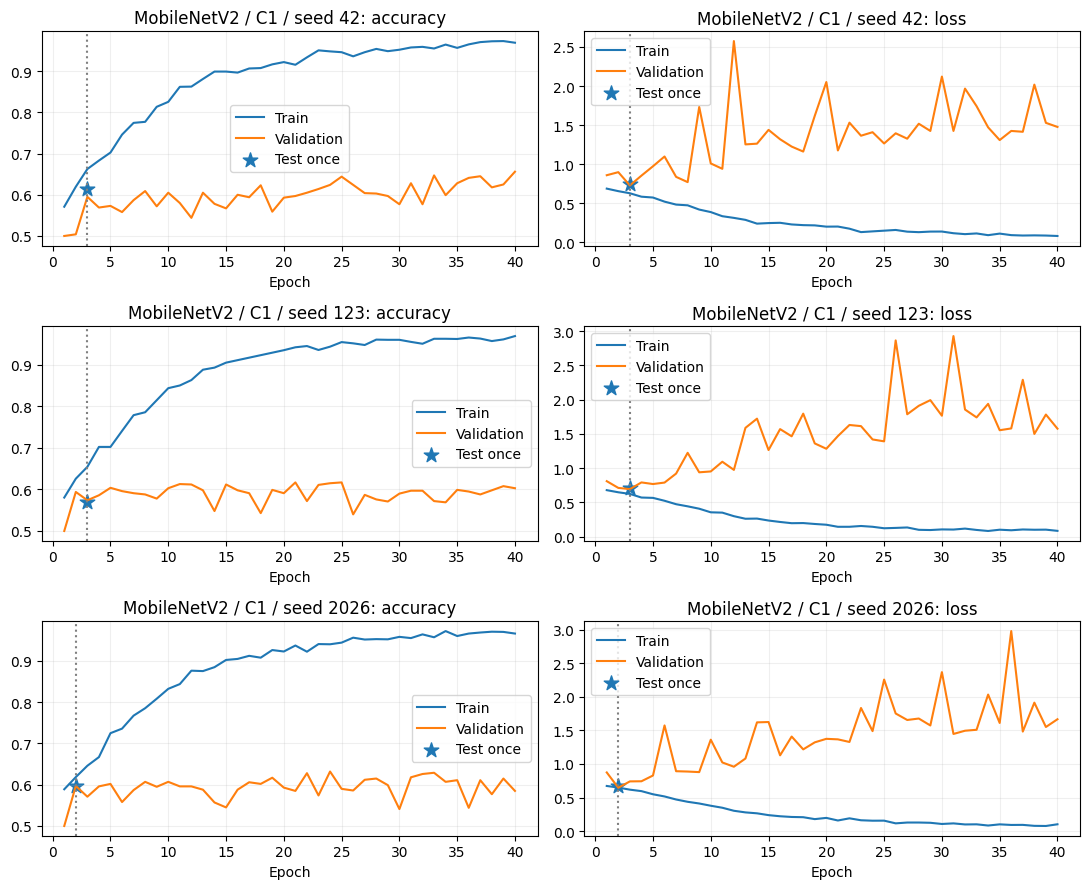

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,3,0.6625,0.595,0.614,0.626005,0.726471,0.743269
1,123,3,0.6545,0.574,0.571,0.624739,0.694310,0.706743
2,2026,2,0.6185,0.597,0.596,0.648653,0.645924,0.677169


In [ ]:
plot_saved_runs('MobileNetV2', 'C1')

### 저장된 실험 결과: MobileNetV2 / F

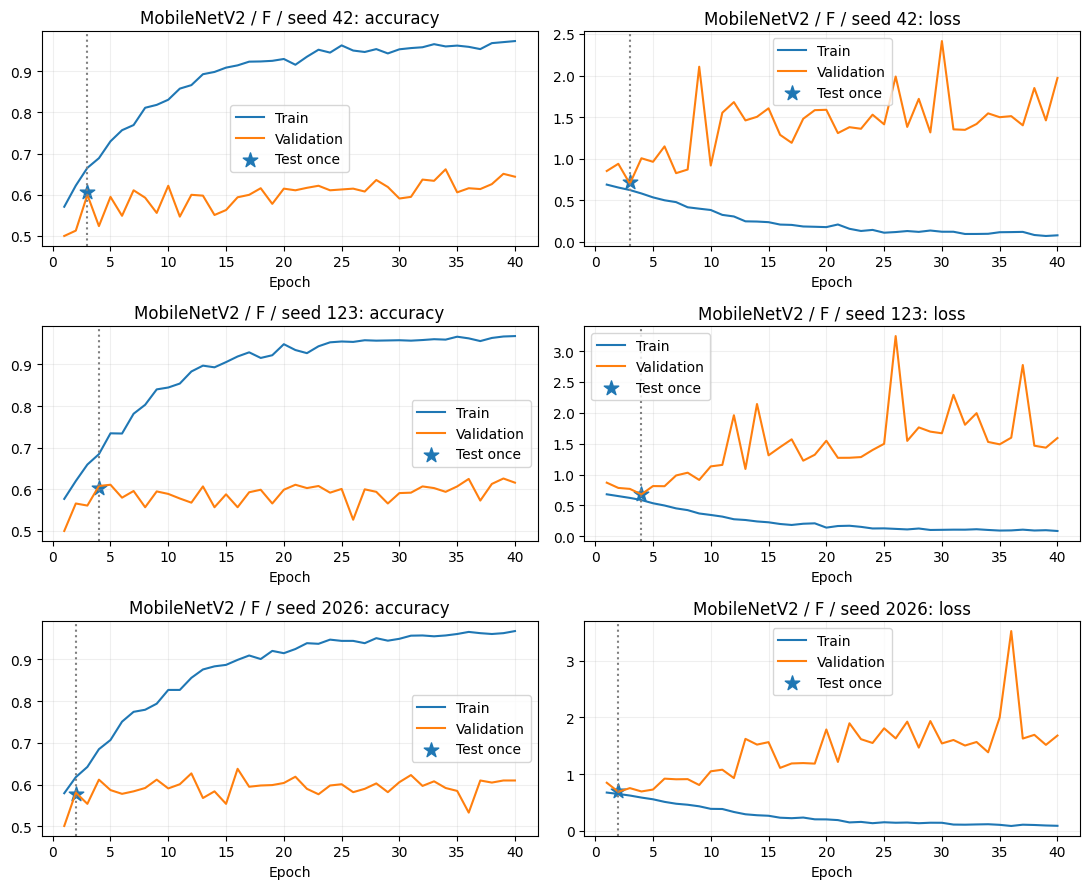

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,3,0.6655,0.600,0.608,0.621887,0.697697,0.719706
1,123,4,0.6845,0.608,0.603,0.587806,0.679859,0.691648
2,2026,2,0.6180,0.581,0.577,0.649916,0.687998,0.702736


In [ ]:
plot_saved_runs('MobileNetV2', 'F')

### 저장된 실험 결과: MobileNetV2 / T

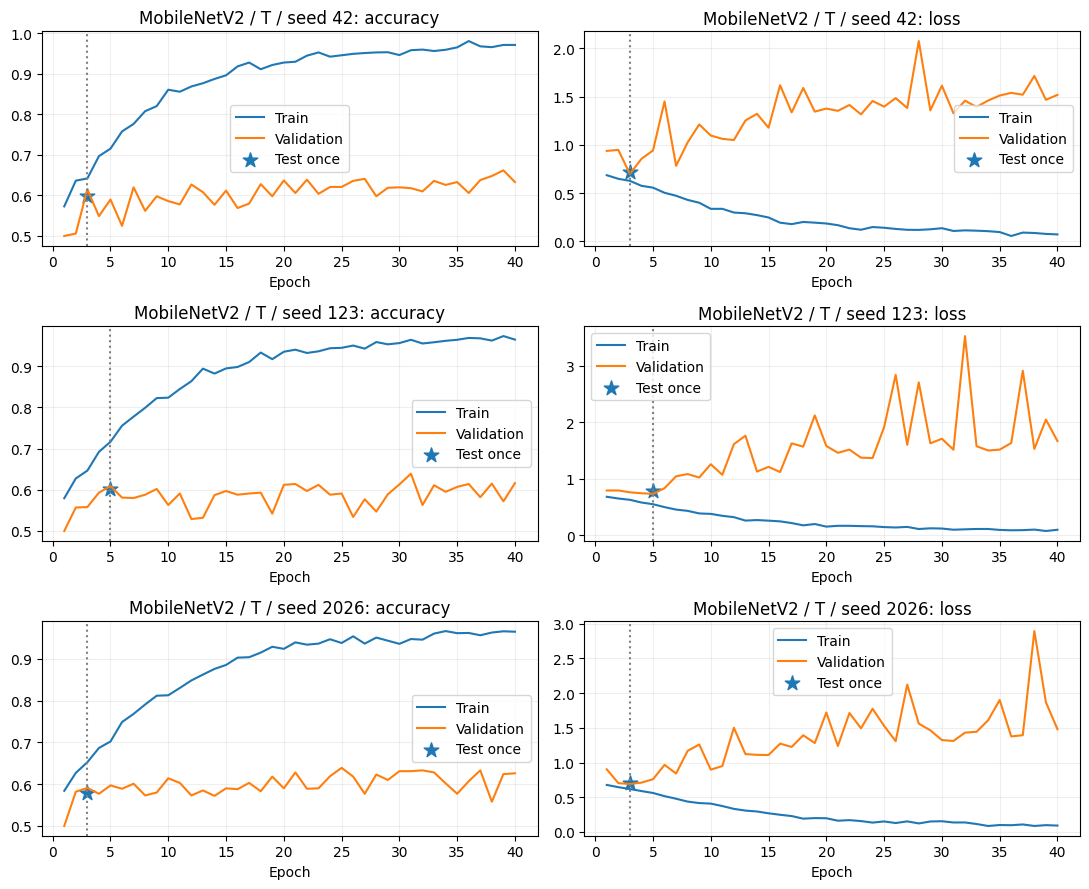

,seed,epoch,train_accuracy,validation_accuracy,test_accuracy,train_loss,validation_loss,test_bce
0,42,3,0.6420,0.615,0.599,0.627206,0.698243,0.723787
1,123,5,0.7165,0.609,0.601,0.549187,0.732889,0.776212
2,2026,3,0.6525,0.591,0.580,0.618131,0.690836,0.701079


In [ ]:
plot_saved_runs('MobileNetV2', 'T')

## 공식 benchmark 평가 (선택)
실행 번호 [44]·[45]의 FileNotFoundError를 수정했습니다. 모델과 benchmark 이미지가 준비된 경우에만 기존 평가 코드를 실행합니다.
기본 검색 위치는 제출 폴더/benchmark, 다음은 데이터셋 폴더/benchmark입니다. 다른 위치는 아래 BENCHMARK_ROOT에 지정합니다. benchmark 폴더 이름은 benchmark여야 합니다.
보호 코드의 계산 내용은 유지하고 실행 조건만 추가했습니다. 150×150, 1/255, batch_size=1, steps=2000은 같습니다. 공식 데이터가 없으면 미평가이며 test 데이터로 대체하지 않습니다.


In [ ]:
# 공식 benchmark가 없으면 평가를 건너뜁니다.
import os
from pathlib import Path
from os.path import join
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 교수님 데이터가 다른 곳에 있다면 benchmark 폴더 자체의 경로를 지정하세요.
# 예: BENCHMARK_ROOT = Path('/content/drive/MyDrive/20213589_김준석/benchmark')
BENCHMARK_ROOT = None
candidates = ([Path(BENCHMARK_ROOT)] if BENCHMARK_ROOT is not None
              else [Path(BUNDLE_DIR) / 'benchmark', Path(SOURCE_ROOT) / 'benchmark'])
benchmark_root = next(
    (p for p in candidates if all((p / cls).is_dir() for cls in ('cats', 'dogs'))),
    candidates[0]
)
base_dir = str(benchmark_root.parent)
save_directory = str(BUNDLE_DIR)
submission_model_path = Path(save_directory) / '20213589_김준석.h5'
extensions = {'.png', '.jpg', '.jpeg', '.bmp', '.ppm', '.tif', '.tiff'}
counts = {cls: sum(p.is_file() and p.suffix.lower() in extensions
                   for p in (benchmark_root / cls).rglob('*'))
          for cls in ('cats', 'dogs')}
BENCHMARK_READY = (submission_model_path.is_file()
                   and all(counts.values()) and sum(counts.values()) >= 2000)
print('공식 benchmark 위치:', benchmark_root)
print('평가 모델:', submission_model_path)
print('클래스별 이미지 수:', counts)
if not BENCHMARK_READY:
    print('공식 benchmark 평가 미실행: 모델 파일과 cats/dogs 이미지 총 2,000개 이상이 필요합니다.')
    print('교수님 benchmark 데이터를 연결한 후 이 셀과 다음 셀을 다시 실행하세요.')
    print('기존 test 평가와 학습 로그는 별개이며, benchmark 점수를 대신 생성하지 않습니다.')


공식 benchmark 위치: /content/drive/MyDrive/Colab Notebooks/20213589_김준석/benchmark
평가 모델: /content/drive/MyDrive/Colab Notebooks/20213589_김준석/20213589_김준석.h5
클래스별 이미지 수: {'cats': 0, 'dogs': 0}
공식 benchmark 평가 미실행: 모델 파일과 cats/dogs 이미지 총 2,000개 이상이 필요합니다.
교수님 benchmark 데이터를 연결한 후 이 셀과 다음 셀을 다시 실행하세요.
기존 test 평가와 학습 로그는 별개이며, benchmark 점수를 대신 생성하지 않습니다.


In [ ]:
if globals().get('BENCHMARK_READY', False):
    ##################################
    ### 여기 아래는 건들지 마세요 ####
    ##################################

    # Assuming the benchmark dataset is in a directory named 'benchmark_dataset' within the base directory.
    benchmark_dir = join(base_dir, 'benchmark')

    benchmark_datagen = ImageDataGenerator(rescale=1./255)

    benchmark_generator = benchmark_datagen.flow_from_directory(
            benchmark_dir,
            target_size=(150, 150),
            batch_size=1,
            class_mode='binary')

    # Load the entire model from the specified directory
    loaded_model_full = tf.keras.models.load_model(os.path.join(save_directory, '20213589_김준석.h5'))

    # Evaluate the loaded model
    test_loss_full, test_acc_full = loaded_model_full.evaluate(benchmark_generator, steps=2000)
    print('Test accuracy after loading the entire model from save_directory:', test_acc_full)
else:
    print('공식 benchmark 평가를 건너뛰었습니다. 앞 셀에서 데이터 경로를 확인하세요.')


공식 benchmark 평가를 건너뛰었습니다. 앞 셀에서 데이터 경로를 확인하세요.


## 재현 범위와 작성 지원
실험 기록은 2026-10-30에 완료된 60회의 결과입니다. 이 제출용 노트북은 읽기 순서·경로 설정·오류 메시지를 정리한 버전입니다. 전체 60회 재학습을 이 파일에서 다시 수행하지 않았으며, 정리 코드의 문법·모델 생성·증강·1배치 학습 및 HDF5 재로딩은 별도로 검사했습니다. 재실행 시 하드웨어 및 라이브러리 차이로 수치가 완전히 같지 않을 수 있습니다. ChatGPT/Codex는 코드 정리, 검증, 결과 시각화와 문서 작성에 사용되었습니다. 수치 결과는 저장된 실험 기록에서 가져왔습니다.